# Phase 3 — Exploratory data analysis

## Research objective
Describe activity distributions, coverage, sleep-log alignment, recorded-time accounting and exploratory outliers without causal or medical claims. Prerequisites: Phase 2 processed daily activity and minute-sleep data. Implementations are transferred into separate cells; the analysis is unfolded into sequential research steps so intermediate calculations and validation are visible. Outputs go to temporary scratch directories.

In [1]:
from pathlib import Path
import tempfile, json, csv, hashlib, statistics, math, sys
from IPython.display import display, HTML, SVG
def find_project_root(start=Path.cwd()):
    for candidate in (start,*start.parents):
        if (candidate/'data/raw').is_dir() and (candidate/'src').is_dir(): return candidate
    raise RuntimeError('Run this notebook from the FitInsight repository or a child directory')
ROOT=find_project_root()
print('Repository:',ROOT)

Repository: /home/runner/workspace/Fitinsight


## Inspect the study inputs

In [2]:
daily_path=ROOT/'data/processed/daily_activity_clean.csv'
sleep_path=ROOT/'data/processed/minute_sleep_clean.csv'
print('Daily input:',daily_path.stat().st_size,'bytes; sleep input:',sleep_path.stat().st_size,'bytes')

Daily input: 69070 bytes; sleep input: 11089939 bytes


## Episode construction and validated SVG drawing methods

In [3]:
"""Memory-conscious, neutral-label analysis of processed sleep-minute records."""

from __future__ import annotations

import csv
import sqlite3
import tempfile
from collections import Counter, defaultdict
from datetime import datetime
from pathlib import Path
from typing import Iterable, Iterator


EXPECTED_COLUMNS = ["id", "date", "value", "log_id", "calendar_date"]
TIMESTAMP_FORMAT = "%Y-%m-%d %H:%M:%S"
OVERNIGHT_END_HOUR = 12
OVERNIGHT_START_LATE_HOUR = 18
OVERNIGHT_START_EARLY_HOUR = 6
MAX_OVERNIGHT_SPAN_MINUTES = 12 * 60

In [4]:
from __future__ import annotations
def parse_iso_timestamp(value: str) -> datetime:
    return datetime.strptime(value, TIMESTAMP_FORMAT)

In [5]:
from __future__ import annotations
def iter_episodes(records: Iterable[tuple[str, str, str, str]]) -> Iterator[dict]:
    """Aggregate sorted (id, log_id, timestamp, value) records into log episodes."""
    current_key: tuple[str, str] | None = None
    session: dict | None = None

    def finish(item: dict) -> dict:
        start: datetime = item["start"]
        end: datetime = item["end"]
        span_seconds = (end - start).total_seconds()
        span_minutes = span_seconds / 60
        flags = []
        if item["gap_intervals"]:
            flags.append("timestamp_gap_over_60_seconds")
        if item["nonminute_intervals"]:
            flags.append("interval_not_60_seconds")
        if span_minutes > MAX_OVERNIGHT_SPAN_MINUTES:
            flags.append("elapsed_span_over_12_hours")
        if 12 <= start.hour < 18:
            flags.append("afternoon_start_candidate")
        if end.hour >= OVERNIGHT_END_HOUR:
            flags.append("ends_at_or_after_noon")
        crosses_midnight = start.date() != end.date()
        overnight_time_candidate = (
            end.hour < OVERNIGHT_END_HOUR
            and (
                start.hour >= OVERNIGHT_START_LATE_HOUR
                or start.hour < OVERNIGHT_START_EARLY_HOUR
            )
            and span_minutes <= MAX_OVERNIGHT_SPAN_MINUTES
            and item["gap_intervals"] == 0
            and item["nonminute_intervals"] == 0
        )
        category_counts = dict(sorted(item["categories"].items()))
        category_shares = {
            category: count / item["record_count"]
            for category, count in category_counts.items()
        }
        result = {
            "id": item["id"],
            "log_id": item["log_id"],
            "start_timestamp": start.strftime(TIMESTAMP_FORMAT),
            "end_timestamp": end.strftime(TIMESTAMP_FORMAT),
            "waking_date": end.date().isoformat(),
            "recorded_minute_count": item["record_count"],
            "elapsed_span_minutes": span_minutes,
            "crosses_midnight": crosses_midnight,
            "start_hour": start.hour,
            "end_hour": end.hour,
            "gap_intervals_over_60_seconds": item["gap_intervals"],
            "intervals_not_60_seconds": item["nonminute_intervals"],
            "category_counts": category_counts,
            "category_shares": category_shares,
            "quality_flags": flags,
            "overnight_time_candidate": overnight_time_candidate,
            "overnight_candidate": overnight_time_candidate,
            "primary_eligible": False,
            "primary_exclusion_reason": "",
            "_start": start,
            "_end": end,
        }
        return result

    for participant_id, log_id, timestamp, value in records:
        key = (participant_id, log_id)
        moment = (
            timestamp
            if isinstance(timestamp, datetime)
            else parse_iso_timestamp(timestamp)
        )
        if key != current_key:
            if session is not None:
                yield finish(session)
            current_key = key
            session = {
                "id": participant_id,
                "log_id": log_id,
                "start": moment,
                "end": moment,
                "record_count": 0,
                "gap_intervals": 0,
                "nonminute_intervals": 0,
                "categories": Counter(),
            }
        else:
            interval = (moment - session["end"]).total_seconds()
            if interval > 60:
                session["gap_intervals"] += 1
            if interval != 60:
                session["nonminute_intervals"] += 1
            session["end"] = moment
        session["record_count"] += 1
        session["categories"][value] += 1
    if session is not None:
        yield finish(session)

In [6]:
from __future__ import annotations
def identify_overlaps(episodes: list[dict]) -> list[dict]:
    """Flag every episode that overlaps another episode for the same participant."""
    ordered = sorted(episodes, key=lambda item: (item["id"], item["_start"], item["log_id"]))
    active_by_participant: dict[str, list[dict]] = defaultdict(list)
    for episode in ordered:
        active = active_by_participant[episode["id"]]
        active[:] = [prior for prior in active if prior["_end"] >= episode["_start"]]
        for prior in active:
            if episode["_start"] <= prior["_end"] and prior["_start"] <= episode["_end"]:
                if "overlaps_another_log" not in prior["quality_flags"]:
                    prior["quality_flags"].append("overlaps_another_log")
                if "overlaps_another_log" not in episode["quality_flags"]:
                    episode["quality_flags"].append("overlaps_another_log")
        active.append(episode)
    return episodes

In [7]:
from __future__ import annotations
def assign_primary_eligibility(episodes: list[dict]) -> dict:
    candidates_by_date: dict[tuple[str, str], list[dict]] = defaultdict(list)
    for episode in episodes:
        if episode["overnight_candidate"]:
            candidates_by_date[(episode["id"], episode["waking_date"])].append(episode)

    ambiguous_dates = {
        key for key, items in candidates_by_date.items() if len(items) > 1
    }
    for key in ambiguous_dates:
        for episode in candidates_by_date[key]:
            if "multiple_overnight_logs_same_waking_date" not in episode["quality_flags"]:
                episode["quality_flags"].append("multiple_overnight_logs_same_waking_date")

    for episode in episodes:
        if not episode["overnight_candidate"]:
            if "afternoon_start_candidate" in episode["quality_flags"]:
                episode["primary_exclusion_reason"] = "potential_daytime_or_afternoon_session"
            elif "elapsed_span_over_12_hours" in episode["quality_flags"]:
                episode["primary_exclusion_reason"] = "elapsed_span_over_12_hours"
            elif "ends_at_or_after_noon" in episode["quality_flags"]:
                episode["primary_exclusion_reason"] = "ends_at_or_after_noon"
            else:
                episode["primary_exclusion_reason"] = "start_time_not_in_overnight_window"
            continue
        if (episode["id"], episode["waking_date"]) in ambiguous_dates:
            episode["primary_exclusion_reason"] = "multiple_overnight_logs_same_waking_date"
        elif "overlaps_another_log" in episode["quality_flags"]:
            episode["primary_exclusion_reason"] = "overlapping_log"
        elif episode["gap_intervals_over_60_seconds"] or episode["intervals_not_60_seconds"]:
            episode["primary_exclusion_reason"] = "irregular_timestamp_intervals"
        else:
            episode["primary_eligible"] = True

    return {
        "overnight_candidate_count": sum(bool(e["overnight_candidate"]) for e in episodes),
        "primary_eligible_episode_count": sum(bool(e["primary_eligible"]) for e in episodes),
        "multiple_overnight_waking_dates": len(ambiguous_dates),
        "sessions_on_multiple_overnight_waking_dates": sum(
            len(items) for key, items in candidates_by_date.items() if key in ambiguous_dates
        ),
    }

In [8]:
from __future__ import annotations
def analyze_sleep_csv(path: Path) -> dict:
    """Read one processed sleep file, aggregate in SQLite, and return compact outputs."""
    if not path.is_file():
        raise FileNotFoundError(path)
    category_counts: Counter[str] = Counter()
    coverage: dict[str, dict] = {}
    raw_rows = 0
    duplicate_rows = 0
    conflicting_duplicate_rows = 0
    calendar_date_mismatches = 0

    with tempfile.TemporaryDirectory(prefix="fitinsight-p3-sleep-") as temp_dir:
        database = Path(temp_dir) / "sleep.sqlite"
        connection = sqlite3.connect(database)
        try:
            connection.execute("PRAGMA journal_mode=OFF")
            connection.execute("PRAGMA synchronous=OFF")
            connection.execute(
                "CREATE TABLE sleep_records ("
                "id TEXT NOT NULL, log_id TEXT NOT NULL, timestamp TEXT NOT NULL, "
                "value TEXT NOT NULL, PRIMARY KEY(id, log_id, timestamp))"
            )
            with path.open("r", encoding="utf-8-sig", newline="") as stream:
                reader = csv.DictReader(stream)
                if reader.fieldnames != EXPECTED_COLUMNS:
                    raise ValueError(
                        f"Unexpected sleep columns: {reader.fieldnames!r}; "
                        f"expected {EXPECTED_COLUMNS!r}"
                    )
                for row in reader:
                    raw_rows += 1
                    participant_id = row["id"]
                    log_id = row["log_id"]
                    moment = parse_iso_timestamp(row["date"])
                    if not participant_id or not log_id:
                        raise ValueError("Sleep row is missing id or log_id")
                    if row["calendar_date"] != moment.date().isoformat():
                        calendar_date_mismatches += 1
                    category_counts[row["value"]] += 1
                    cursor = connection.execute(
                        "INSERT OR IGNORE INTO sleep_records VALUES (?, ?, ?, ?)",
                        (participant_id, log_id, row["date"], row["value"]),
                    )
                    if cursor.rowcount == 0:
                        duplicate_rows += 1
                        existing = connection.execute(
                            "SELECT value FROM sleep_records "
                            "WHERE id=? AND log_id=? AND timestamp=?",
                            (participant_id, log_id, row["date"]),
                        ).fetchone()
                        if existing is not None and existing[0] != row["value"]:
                            conflicting_duplicate_rows += 1
                    part = coverage.setdefault(
                        participant_id,
                        {"id": participant_id, "records": 0, "logs": set(),
                         "first_timestamp": row["date"], "last_timestamp": row["date"]},
                    )
                    part["records"] += 1
                    part["logs"].add(log_id)
                    part["first_timestamp"] = min(part["first_timestamp"], row["date"])
                    part["last_timestamp"] = max(part["last_timestamp"], row["date"])

            connection.commit()
            connection.execute(
                "CREATE INDEX sleep_episode_order "
                "ON sleep_records(id, log_id, timestamp)"
            )
            records = connection.execute(
                "SELECT id, log_id, timestamp, value FROM sleep_records "
                "ORDER BY id, log_id, timestamp"
            )
            episodes = list(iter_episodes(records))
            distinct_rows = connection.execute(
                "SELECT COUNT(*) FROM sleep_records"
            ).fetchone()[0]
            distinct_log_ids = connection.execute(
                "SELECT COUNT(DISTINCT log_id) FROM sleep_records"
            ).fetchone()[0]
            reused_log_ids = connection.execute(
                "SELECT COUNT(*) FROM (SELECT log_id FROM sleep_records "
                "GROUP BY log_id HAVING COUNT(DISTINCT id)>1)"
            ).fetchone()[0]
        finally:
            connection.close()

    identify_overlaps(episodes)
    eligibility = assign_primary_eligibility(episodes)
    for participant in coverage.values():
        participant["logs"] = len(participant["logs"])

    metrics = {
        "input_file": str(path),
        "input_rows": raw_rows,
        "distinct_rows": distinct_rows,
        "duplicate_key_rows_after_preprocessing": duplicate_rows,
        "conflicting_duplicate_rows": conflicting_duplicate_rows,
        "participants": len(coverage),
        "distinct_log_id_values": distinct_log_ids,
        "participant_log_groups": len(episodes),
        "log_ids_reused_across_participants": reused_log_ids,
        "timestamp_to_calendar_date_mismatches": calendar_date_mismatches,
        "value_category_counts": dict(sorted(category_counts.items())),
        "cross_midnight_logs": sum(bool(e["crosses_midnight"]) for e in episodes),
        "logs_over_12_hours": sum(
            "elapsed_span_over_12_hours" in e["quality_flags"] for e in episodes
        ),
        "potential_afternoon_start_logs": sum(
            "afternoon_start_candidate" in e["quality_flags"] for e in episodes
        ),
        "logs_with_timestamp_gap_over_60_seconds": sum(
            e["gap_intervals_over_60_seconds"] > 0 for e in episodes
        ),
        "logs_with_non_60_second_intervals": sum(
            e["intervals_not_60_seconds"] > 0 for e in episodes
        ),
        "overlapping_log_count": sum(
            "overlaps_another_log" in e["quality_flags"] for e in episodes
        ),
        **eligibility,
        "interpretation": (
            "Value categories are reported as their stored codes only; their sleep-state "
            "meaning is not established by repository documentation."
        ),
    }
    return {
        "metrics": metrics,
        "episodes": episodes,
        "participant_coverage": sorted(coverage.values(), key=lambda item: item["id"]),
    }

In [9]:
from __future__ import annotations
def strip_internal_episode_fields(episode: dict) -> dict:
    """Return serializable episode fields without datetime helper objects."""
    return {key: value for key, value in episode.items() if not key.startswith("_")}

In [10]:
"""Deterministic, dependency-free SVG figures for Phase 3."""

from __future__ import annotations

import html
import math
from datetime import date
from pathlib import Path
from typing import Any


PALETTE = {
    "cyan": "#61A9BD",
    "yellow": "#CED14E",
    "green": "#44986D",
    "pink": "#DD83C9",
    "blue": "#1F74AD",
    "orange": "#E98E2E",
    "purple": "#9267C6",
    "brown": "#8D6C5B",
    "red": "#D8524F",
    "grey": "#979797",
    "dark": "#17324D",
    "muted": "#5E7184",
    "grid": "#E5ECF1",
    "paper": "#FFFFFF",
}

In [11]:
from __future__ import annotations
def esc(value: Any) -> str:
    return html.escape(str(value), quote=True)

In [12]:
from __future__ import annotations
class Svg:
    def __init__(self, title: str, subtitle: str, note: str, width: int = 1120, height: int = 720):
        self.width = width
        self.height = height
        self.parts = [
            f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" '
            f'viewBox="0 0 {width} {height}" role="img" aria-label="{esc(title)}">',
            f"<title>{esc(title)}</title>",
            f"<desc>{esc(subtitle)}. {esc(note)}</desc>",
            f'<rect x="0" y="0" width="{width}" height="{height}" fill="{PALETTE["paper"]}"/>',
            f'<text x="72" y="58" font-family="Arial, sans-serif" font-size="28" '
            f'font-weight="700" fill="{PALETTE["dark"]}">{esc(title)}</text>',
            f'<text x="72" y="91" font-family="Arial, sans-serif" font-size="15" '
            f'fill="{PALETTE["muted"]}">{esc(subtitle)}</text>',
        ]
        self.note = note

    def line(self, x1: float, y1: float, x2: float, y2: float, color: str, width: float = 1, dash: str = ""):
        dash_attr = f' stroke-dasharray="{dash}"' if dash else ""
        self.parts.append(
            f'<line x1="{x1:.2f}" y1="{y1:.2f}" x2="{x2:.2f}" y2="{y2:.2f}" '
            f'stroke="{color}" stroke-width="{width}"{dash_attr}/>'
        )

    def rect(self, x: float, y: float, width: float, height: float, fill: str, rx: float = 0, stroke: str = "none"):
        self.parts.append(
            f'<rect x="{x:.2f}" y="{y:.2f}" width="{width:.2f}" height="{height:.2f}" '
            f'rx="{rx:.2f}" fill="{fill}" stroke="{stroke}"/>'
        )

    def circle(self, x: float, y: float, radius: float, fill: str, opacity: float = 1):
        self.parts.append(
            f'<circle cx="{x:.2f}" cy="{y:.2f}" r="{radius:.2f}" fill="{fill}" '
            f'fill-opacity="{opacity:.2f}"/>'
        )

    def path(self, points: list[tuple[float, float]], stroke: str, width: float = 2, opacity: float = 1):
        if not points:
            return
        d = " ".join(
            ("M" if index == 0 else "L") + f" {x:.2f} {y:.2f}"
            for index, (x, y) in enumerate(points)
        )
        self.parts.append(
            f'<path d="{d}" fill="none" stroke="{stroke}" stroke-width="{width}" '
            f'stroke-linecap="round" stroke-linejoin="round" stroke-opacity="{opacity:.2f}"/>'
        )

    def text(
        self,
        x: float,
        y: float,
        value: Any,
        size: int = 13,
        color: str | None = None,
        anchor: str = "start",
        weight: str = "400",
        rotate: float | None = None,
    ):
        color = color or PALETTE["muted"]
        transform = f' transform="rotate({rotate:.1f} {x:.2f} {y:.2f})"' if rotate is not None else ""
        self.parts.append(
            f'<text x="{x:.2f}" y="{y:.2f}" font-family="Arial, sans-serif" '
            f'font-size="{size}" font-weight="{weight}" text-anchor="{anchor}" '
            f'fill="{color}"{transform}>{esc(value)}</text>'
        )

    def footer(self):
        self.line(72, self.height - 58, self.width - 72, self.height - 58, PALETTE["grid"], 1)
        self.text(72, self.height - 32, self.note, 12)
        self.parts.append("</svg>")
        return "\n".join(self.parts) + "\n"

In [13]:
from __future__ import annotations
def nice_max(value: float) -> float:
    if value <= 0:
        return 1
    exponent = 10 ** math.floor(math.log10(value))
    fraction = value / exponent
    step = 1 if fraction <= 1 else 2 if fraction <= 2 else 5 if fraction <= 5 else 10
    return step * exponent

In [14]:
from __future__ import annotations
def y_axis(svg: Svg, x: float, y: float, width: float, height: float, maximum: float, ticks: int = 5):
    top = y
    bottom = y + height
    for index in range(ticks + 1):
        value = maximum * index / ticks
        yy = bottom - height * index / ticks
        svg.line(x, yy, x + width, yy, PALETTE["grid"], 1)
        svg.text(x - 12, yy + 4, f"{value:,.0f}", 12, anchor="end")
    svg.line(x, top, x, bottom, PALETTE["muted"], 1)
    svg.line(x, bottom, x + width, bottom, PALETTE["muted"], 1)

In [15]:
from __future__ import annotations
def histogram(values: list[float], bins: int = 12, maximum: float | None = None):
    maximum = maximum or max(values, default=1)
    maximum = max(maximum, 1)
    width = maximum / bins
    counts = [0] * bins
    for value in values:
        index = min(int(value / width), bins - 1)
        counts[max(index, 0)] += 1
    return counts, width, maximum

In [16]:
from __future__ import annotations
def step_histogram(rows: list[dict], output_dir: Path) -> dict:
    values = [float(row["total_steps"]) for row in rows if row["total_steps"] is not None]
    counts, bin_width, max_value = histogram(values, bins=12, maximum=30000)
    maximum_count = nice_max(max(counts, default=1))
    svg = Svg(
        "Daily step counts are right-skewed",
        "Distribution across recorded participant-days",
        f"n={len(values)} participant-days; 2,500-step bins; historical records, not a population estimate.",
    )
    x, y, width, height = 104, 150, 930, 410
    y_axis(svg, x, y, width, height, maximum_count)
    bar_width = width / len(counts)
    for index, count in enumerate(counts):
        bar_height = height * count / maximum_count
        bx = x + index * bar_width + 3
        svg.rect(bx, y + height - bar_height, bar_width - 6, bar_height, PALETTE["cyan"], 4)
        if index % 2 == 0:
            svg.text(bx + (bar_width - 6) / 2, y + height + 23, f"{int(index * bin_width / 1000)}k", 12, anchor="middle")
    svg.text(x + width / 2, y + height + 50, "Recorded steps per participant-day", 14, anchor="middle")
    svg.text(34, y + height / 2, "Participant-day records", 13, rotate=-90, anchor="middle")
    path = output_dir / "01_daily_steps_distribution.svg"
    path.write_text(svg.footer(), encoding="utf-8")
    return {
        "file": path.name,
        "title": "Daily step counts are right-skewed",
        "sample_count": len(values),
        "interpretation": "Most recorded days fall in lower step-count bins with a right tail.",
        "size_bytes": path.stat().st_size,
    }

In [17]:
from __future__ import annotations
def completeness_histogram(rows: list[dict], output_dir: Path) -> dict:
    groups = {
        "Complete": [float(r["total_steps"]) for r in rows if r["is_complete_day"] is True],
        "Incomplete": [float(r["total_steps"]) for r in rows if r["is_complete_day"] is False],
    }
    maximum = 30000
    bins = 10
    bin_width = maximum / bins
    counts = {}
    for label, values in groups.items():
        series, _, _ = histogram(values, bins=bins, maximum=maximum)
        counts[label] = series
    y_max = nice_max(max(max(v) for v in counts.values()))
    svg = Svg(
        "Step-count distributions differ by completeness",
        "Participant-day counts by recorded-step bin",
        f"Complete n={len(groups['Complete'])}; incomplete n={len(groups['Incomplete'])}; "
        "completeness means 1,440 recorded minutes, not valid/invalid behavior.",
    )
    x, y, width, height = 112, 150, 910, 400
    y_axis(svg, x, y, width, height, y_max)
    category_width = width / bins
    each = category_width * 0.36
    colors = {"Complete": PALETTE["blue"], "Incomplete": PALETTE["orange"]}
    for index in range(bins):
        center = x + (index + 0.5) * category_width
        for shift, label in ((-each / 2, "Complete"), (each / 2, "Incomplete")):
            count = counts[label][index]
            bar_height = height * count / y_max
            svg.rect(
                center + shift - each / 2,
                y + height - bar_height,
                each - 2,
                bar_height,
                colors[label],
                3,
            )
        if index % 2 == 0:
            svg.text(center, y + height + 23, f"{int(index * bin_width / 1000)}k", 12, anchor="middle")
    legend_y = 127
    for index, label in enumerate(("Complete", "Incomplete")):
        lx = 770 + index * 145
        svg.rect(lx, legend_y - 12, 14, 14, colors[label], 3)
        svg.text(lx + 22, legend_y, label, 13)
    svg.text(x + width / 2, y + height + 50, "Recorded steps per participant-day", 14, anchor="middle")
    svg.text(34, y + height / 2, "Participant-day records", 13, rotate=-90, anchor="middle")
    path = output_dir / "02_steps_by_completeness.svg"
    path.write_text(svg.footer(), encoding="utf-8")
    return {
        "file": path.name,
        "title": "Step-count distributions differ by completeness",
        "sample_count": sum(map(len, groups.values())),
        "interpretation": "The two day groups have different distributions; the filter is a sensitivity comparison.",
        "size_bytes": path.stat().st_size,
    }

In [18]:
from __future__ import annotations
def daily_trend_coverage(rows: list[dict], output_dir: Path) -> dict:
    by_date: dict[date, list[dict]] = {}
    for row in rows:
        by_date.setdefault(row["activity_date"], []).append(row)
    summary = [
        {
            "date": day,
            "mean": sum(r["total_steps"] for r in group) / len(group),
            "participants": len({r["id"] for r in group}),
        }
        for day, group in sorted(by_date.items())
    ]
    svg = Svg(
        "Daily step averages need their coverage context",
        "Mean recorded steps and distinct participants per calendar date",
        f"{len(rows)} participant-days across {len(summary)} dates; the daily cohort changes over time.",
    )
    x, w = 105, 920
    top_y, top_h = 155, 245
    bottom_y, bottom_h = 450, 100
    max_steps = nice_max(max(item["mean"] for item in summary))
    y_axis(svg, x, top_y, w, top_h, max_steps)
    points = []
    for index, item in enumerate(summary):
        px = x + (index / max(len(summary) - 1, 1)) * w
        py = top_y + top_h - (item["mean"] / max_steps) * top_h
        points.append((px, py))
    svg.path(points, PALETTE["blue"], 3)
    for px, py in points[::4]:
        svg.circle(px, py, 3.5, PALETTE["blue"])
    svg.text(x, top_y - 16, "Mean recorded steps", 14, weight="700", color=PALETTE["dark"])
    participants_max = max(item["participants"] for item in summary)
    svg.line(x, bottom_y + bottom_h, x + w, bottom_y + bottom_h, PALETTE["muted"], 1)
    for index, item in enumerate(summary):
        cell_width = w / len(summary)
        bar_height = bottom_h * item["participants"] / max(participants_max, 1)
        svg.rect(
            x + index * cell_width + 1,
            bottom_y + bottom_h - bar_height,
            max(cell_width - 2, 1),
            bar_height,
            PALETTE["green"],
            1,
        )
    svg.text(x, bottom_y - 14, "Distinct participant coverage", 14, weight="700", color=PALETTE["dark"])
    svg.text(x, bottom_y + bottom_h + 25, summary[0]["date"].strftime("%b %d"), 12)
    svg.text(x + w, bottom_y + bottom_h + 25, summary[-1]["date"].strftime("%b %d"), 12, anchor="end")
    svg.text(x + w / 2, bottom_y + bottom_h + 25, "2016 observation dates", 12, anchor="middle")
    path = output_dir / "03_daily_steps_and_coverage.svg"
    path.write_text(svg.footer(), encoding="utf-8")
    return {
        "file": path.name,
        "title": "Daily step averages need their coverage context",
        "sample_count": len(rows),
        "interpretation": "Date-level means should be read alongside the changing participant count.",
        "size_bytes": path.stat().st_size,
    }

In [19]:
from __future__ import annotations
def paired_weekday_svg(participant_rows: list[dict], output_dir: Path) -> dict:
    valid = [
        row for row in participant_rows
        if row["weekday_mean_total_steps"] is not None
        and row["weekend_mean_total_steps"] is not None
    ]
    values = [
        row["weekday_mean_total_steps"] for row in valid
    ] + [
        row["weekend_mean_total_steps"] for row in valid
    ]
    maximum = nice_max(max(values, default=1))
    svg = Svg(
        "Weekend and weekday means vary by participant",
        "Paired participant mean steps, with one line per participant",
        f"{len(valid)} participants have both weekday and weekend records; direction is descriptive.",
    )
    x, y, width, height = 150, 155, 820, 390
    y_axis(svg, x, y, width, height, maximum)
    x1, x2 = x + 135, x + width - 55
    svg.text(x1, y + height + 34, "Weekday", 14, anchor="middle", weight="700")
    svg.text(x2, y + height + 34, "Weekend", 14, anchor="middle", weight="700")
    positive = negative = equal = 0
    for row in valid:
        a = row["weekday_mean_total_steps"]
        b = row["weekend_mean_total_steps"]
        y1 = y + height - a / maximum * height
        y2 = y + height - b / maximum * height
        color = (
            PALETTE["blue"] if b > a
            else PALETTE["orange"] if b < a
            else PALETTE["grey"]
        )
        positive += b > a
        negative += b < a
        equal += b == a
        svg.line(x1, y1, x2, y2, color, 2, dash="4 3" if b == a else "")
        svg.circle(x1, y1, 3.5, color)
        svg.circle(x2, y2, 3.5, color)
    legend_y = 127
    for index, (label, color) in enumerate((
        ("Weekend mean higher", PALETTE["blue"]),
        ("Weekday mean higher", PALETTE["orange"]),
        ("Equal", PALETTE["grey"]),
    )):
        lx = 560 + index * 160
        svg.line(lx, legend_y - 4, lx + 20, legend_y - 4, color, 3)
        svg.text(lx + 27, legend_y, label, 12)
    svg.text(32, y + height / 2, "Mean recorded steps", 13, rotate=-90, anchor="middle")
    path = output_dir / "04_weekday_weekend_paired_steps.svg"
    path.write_text(svg.footer(), encoding="utf-8")
    return {
        "file": path.name,
        "title": "Weekend and weekday means vary by participant",
        "sample_count": len(valid),
        "interpretation": f"Weekend mean higher for {positive}; weekday higher for {negative}; equal for {equal}.",
        "size_bytes": path.stat().st_size,
    }

In [20]:
from __future__ import annotations
def composition_svg(rows: list[dict], output_dir: Path) -> dict:
    fields = [
        ("very_active_minutes", "Very active", PALETTE["cyan"]),
        ("fairly_active_minutes", "Fairly active", PALETTE["yellow"]),
        ("lightly_active_minutes", "Lightly active", PALETTE["green"]),
        ("sedentary_minutes", "Sedentary", PALETTE["blue"]),
    ]
    groups = {
        "Incomplete": [r for r in rows if r["is_complete_day"] is False],
        "Complete": [r for r in rows if r["is_complete_day"] is True],
    }
    percentages = {}
    for label, group in groups.items():
        component_shares = {name: [] for _, name, _ in fields}
        for row in group:
            values = [row[field] for field, _, _ in fields]
            denominator = sum(value for value in values if value is not None)
            if denominator <= 0:
                continue
            for (field, name, _), value in zip(fields, values):
                component_shares[name].append(100 * value / denominator)
        percentages[label] = {
            name: sum(items) / len(items) if items else 0
            for name, items in component_shares.items()
        }
    svg = Svg(
        "Recorded-time composition differs by completeness",
        "Mean within-day share of the four activity-minute fields",
        "Per-day denominator is very + fairly + lightly active + sedentary minutes; it is not verified waking time.",
    )
    x, y, height = 210, 160, 390
    bar_width = 190
    for center, label in ((x + 130, "Incomplete"), (x + 500, "Complete")):
        svg.line(center - 70, y + height, center + 70, y + height, PALETTE["muted"], 1)
        bottom = y + height
        for _, name, color in fields:
            amount = percentages[label][name]
            segment_height = height * amount / 100
            svg.rect(center - bar_width / 2, bottom - segment_height, bar_width, segment_height, color, 0)
            if segment_height >= 20:
                svg.text(center, bottom - segment_height / 2 + 5, f"{amount:.1f}%", 13, color=PALETTE["dark"], anchor="middle", weight="700")
            bottom -= segment_height
        svg.text(center, y + height + 32, label, 15, color=PALETTE["dark"], anchor="middle", weight="700")
    for index, (_, name, color) in enumerate(fields):
        lx = 690
        ly = 190 + index * 43
        svg.rect(lx, ly - 13, 16, 16, color, 3)
        svg.text(lx + 26, ly, name, 13)
    svg.text(45, y + height / 2, "Share of four recorded fields (%)", 13, rotate=-90, anchor="middle")
    svg.text(x, y + height + 69, f"n={len(groups['Incomplete'])} incomplete days", 12)
    svg.text(x + 370, y + height + 69, f"n={len(groups['Complete'])} complete days", 12)
    path = output_dir / "05_activity_minute_composition.svg"
    path.write_text(svg.footer(), encoding="utf-8")
    return {
        "file": path.name,
        "title": "Recorded-time composition differs by completeness",
        "sample_count": len(rows),
        "interpretation": (
            "The composition denominator is the sum of four recorded minute fields; "
            f"sedentary share is {percentages['Complete']['Sedentary']:.1f}% for complete "
            f"and {percentages['Incomplete']['Sedentary']:.1f}% for incomplete days."
        ),
        "size_bytes": path.stat().st_size,
    }

In [21]:
from __future__ import annotations
def heatmap_color(value: float | None) -> str:
    if value is None:
        return "#D9E0E5"
    if value <= -0.5:
        return "#2672A6"
    if value < 0:
        return "#8AB1CC"
    if value == 0:
        return "#FFFFFF"
    if value < 0.5:
        return "#FAB770"
    return "#E99F2E"

In [22]:
from __future__ import annotations
def correlation_heatmap(correlations: dict, output_dir: Path) -> dict:
    heat = correlations["heatmap"]
    labels = heat["labels"]
    cells = heat["cells"]
    size = 80
    x0, y0 = 350, 170
    svg = Svg(
        "Activity measures show varied rank associations",
        "Spearman correlations across participant-days",
        "Each tile shows Spearman rho and valid pair count; associations are descriptive and repeated days are not independent people.",
        width=1120,
        height=800,
    )
    for index, label in enumerate(labels):
        svg.text(x0 - 13, y0 + index * size + size / 2 + 4, label, 13, anchor="end")
        svg.text(x0 + index * size + size / 2, y0 - 13, label, 12, anchor="middle", rotate=-40)
    for cell in cells:
        x = x0 + cell["x_index"] * size
        y = y0 + cell["y_index"] * size
        value = cell["spearman"]
        svg.rect(x, y, size - 2, size - 2, heatmap_color(value), 5, PALETTE["paper"])
        number = "NA" if value is None else f"{value:.2f}"
        svg.text(x + (size - 2) / 2, y + 42, number, 14, anchor="middle", color=PALETTE["dark"], weight="700")
        svg.text(x + (size - 2) / 2, y + 64, f"n={cell['n_pairs']}", 11, anchor="middle")
    legend_y = y0 + len(labels) * size + 18
    for index, (label, color) in enumerate((
        ("≤ −0.5", "#2672A6"),
        ("−0.5 to 0", "#8AB1CC"),
        ("0", "#FFFFFF"),
        ("0 to 0.5", "#FAB770"),
        ("≥ 0.5", "#E99F2E"),
        ("Missing", "#D9E0E5"),
    )):
        lx = 270 + index * 110
        svg.rect(lx, legend_y, 22, 18, color, 2, PALETTE["grid"])
        svg.text(lx + 29, legend_y + 14, label, 11)
    path = output_dir / "06_activity_correlation_heatmap.svg"
    path.write_text(svg.footer(), encoding="utf-8")
    return {
        "file": path.name,
        "title": "Activity measures show varied rank associations",
        "sample_count": max((cell["n_pairs"] for cell in cells), default=0),
        "interpretation": "The matrix reports rank associations and per-cell sample sizes.",
        "size_bytes": path.stat().st_size,
    }

In [23]:
from __future__ import annotations
def sleep_episode_histogram(episodes: list[dict], output_dir: Path) -> dict:
    values = [float(episode["recorded_minute_count"]) for episode in episodes]
    counts, bin_width, maximum = histogram(values, bins=12, maximum=960)
    y_max = nice_max(max(counts, default=1))
    svg = Svg(
        "Recorded sleep-log sizes vary",
        "Number of rows recorded within each participant-log group",
        f"n={len(values)} logs; x-axis counts minute records, not validated sleep duration; 12 bins.",
    )
    x, y, width, height = 110, 155, 920, 400
    y_axis(svg, x, y, width, height, y_max)
    bar_width = width / len(counts)
    for index, count in enumerate(counts):
        bh = height * count / y_max
        bx = x + index * bar_width + 3
        svg.rect(bx, y + height - bh, bar_width - 6, bh, PALETTE["purple"], 4)
        if index % 2 == 0:
            svg.text(bx + (bar_width - 6) / 2, y + height + 22, f"{int(index * bin_width)}", 11, anchor="middle")
    svg.text(x + width / 2, y + height + 50, "Recorded sleep-minute rows per log", 14, anchor="middle")
    svg.text(35, y + height / 2, "Participant-log episodes", 13, rotate=-90, anchor="middle")
    path = output_dir / "07_recorded_sleep_log_sizes.svg"
    path.write_text(svg.footer(), encoding="utf-8")
    return {
        "file": path.name,
        "title": "Recorded sleep-log sizes vary",
        "sample_count": len(values),
        "interpretation": "Session row counts vary; they are not labeled as actual minutes asleep.",
        "size_bytes": path.stat().st_size,
    }

In [24]:
from __future__ import annotations
def sleep_activity_scatter(matched_rows: list[dict], output_dir: Path) -> dict:
    rows = [
        row for row in matched_rows
        if row["sleep_match_status"] == "matched"
        and row["recorded_sleep_minutes"] is not None
        and row["total_steps"] is not None
    ]
    x_values = [float(row["recorded_sleep_minutes"]) for row in rows]
    y_values = [float(row["total_steps"]) for row in rows]
    max_x = nice_max(max(x_values, default=1))
    max_y = nice_max(max(y_values, default=1))
    svg = Svg(
        "Recorded sleep-log rows and waking-day steps",
        "One point per unique eligible participant-waking date",
        f"n={len(rows)} matched dates; recorded log rows are not validated sleep duration; no causal interpretation.",
    )
    x, y, width, height = 120, 155, 900, 400
    y_axis(svg, x, y, width, height, max_y)
    for index in range(6):
        value = max_x * index / 5
        xx = x + width * index / 5
        svg.line(xx, y + height, xx, y + height + 5, PALETTE["muted"], 1)
        svg.text(xx, y + height + 22, f"{value:.0f}", 11, anchor="middle")
    for x_value, y_value in zip(x_values, y_values):
        px = x + width * x_value / max_x
        py = y + height - height * y_value / max_y
        svg.circle(px, py, 4, PALETTE["cyan"], opacity=0.72)
    svg.text(x + width / 2, y + height + 50, "Recorded sleep-minute rows in episode", 14, anchor="middle")
    svg.text(37, y + height / 2, "Waking-day recorded steps", 13, rotate=-90, anchor="middle")
    path = output_dir / "08_sleep_records_vs_waking_steps.svg"
    path.write_text(svg.footer(), encoding="utf-8")
    return {
        "file": path.name,
        "title": "Recorded sleep-log rows and waking-day steps",
        "sample_count": len(rows),
        "interpretation": "Each point is a unique matched waking date; the chart is descriptive only.",
        "size_bytes": path.stat().st_size,
    }

In [25]:
from __future__ import annotations
def time_accounting_scatter(time_accounting_rows: list[dict], output_dir: Path) -> dict:
    rows = sorted(
        time_accounting_rows,
        key=lambda row: (row["activity_date"], row["id"]),
    )
    dates = sorted({row["activity_date"] for row in rows})
    date_index = {day: index for index, day in enumerate(dates)}
    by_date: dict[str, list[dict]] = {}
    for row in rows:
        by_date.setdefault(row["activity_date"], []).append(row)
    values = [float(row["combined_recorded_minutes"]) for row in rows]
    minimum = 0
    maximum = max(1600, math.ceil(max(values, default=1440) / 200) * 200)
    exact_count = sum(row["combined_equals_1440"] for row in rows)
    within_30 = sum(row["within_30_minutes"] for row in rows)
    svg = Svg(
        "Activity and sleep rows sometimes sum near 1,440",
        "One point per unique eligible participant-waking date",
        f"n={len(rows)} matched days; exact={exact_count}; within 30 minutes={within_30}. "
        "Recorded sleep rows are not validated sleep duration or verified 24-hour coverage.",
    )
    x, y, width, height = 120, 155, 900, 410
    y_axis(svg, x, y, width, height, maximum)
    target_y = y + height - height * 1440 / maximum
    svg.parts.append(
        f'<line x1="{x:.2f}" y1="{target_y:.2f}" x2="{x + width:.2f}" '
        f'y2="{target_y:.2f}" stroke="{PALETTE["red"]}" stroke-width="2" '
        'stroke-dasharray="7 5" data-reference-minutes="1440"/>'
    )
    svg.text(x + width - 4, target_y - 8, "Reference: 1,440", 12,
             anchor="end", color=PALETTE["red"], weight="700")
    for date_position in range(len(dates)):
        xx = x + width * date_position / max(len(dates) - 1, 1)
        svg.line(xx, y + height, xx, y + height + 5, PALETTE["muted"], 1)
    label_positions = sorted(set((0, len(dates) // 2, len(dates) - 1)))
    for position in label_positions:
        xx = x + width * position / max(len(dates) - 1, 1)
        day = dates[position]
        svg.text(xx, y + height + 23, day, 11,
                 anchor="middle" if position != 0 else "start")
    for day, items in by_date.items():
        position = date_index[day]
        group = sorted(items, key=lambda row: row["id"])
        for index, row in enumerate(group):
            jitter = (
                (index + 0.5) / len(group) - 0.5
            ) * min(0.7, 10 / max(len(group), 1))
            xx = x + width * (position + jitter) / max(len(dates) - 1, 1)
            value = float(row["combined_recorded_minutes"])
            yy = y + height - height * (value - minimum) / (maximum - minimum)
            color = PALETTE["red"] if day == "2016-04-12" else PALETTE["cyan"]
            svg.parts.append(
                f'<circle cx="{xx:.2f}" cy="{yy:.2f}" r="4" fill="{color}" '
                f'fill-opacity="0.78" data-date="{esc(day)}" '
                f'data-combined-minutes="{value:.0f}"/>'
            )
    svg.text(x + width / 2, y + height + 51, "Activity waking date", 14, anchor="middle")
    svg.text(36, y + height / 2, "Activity + recorded sleep minutes", 13,
             rotate=-90, anchor="middle")
    path = output_dir / "09_time_accounting_by_date.svg"
    path.write_text(svg.footer(), encoding="utf-8")
    return {
        "file": path.name,
        "title": "Activity and sleep rows sometimes sum near 1,440",
        "sample_count": len(rows),
        "plotted_rows": len(rows),
        "target_minutes": 1440,
        "exact_1440_count": exact_count,
        "within_30_minutes_count": within_30,
        "highlighted_boundary_date": "2016-04-12",
        "interpretation": (
            "The reference is arithmetic only; April 12 is highlighted as a "
            "boundary-date sensitivity, not automatically excluded."
        ),
        "size_bytes": path.stat().st_size,
    }

In [26]:
from __future__ import annotations
def generate_figures(
    *,
    rows: list[dict],
    weekday_participant_rows: list[dict],
    correlations: dict,
    sleep_episodes: list[dict],
    matched_rows: list[dict],
    time_accounting_rows: list[dict],
    output_dir: Path,
) -> list[dict]:
    output_dir.mkdir(parents=True, exist_ok=True)
    if not weekday_participant_rows:
        raise ValueError("Weekday participant pairs are required for the paired figure")

    return [
        step_histogram(rows, output_dir),
        completeness_histogram(rows, output_dir),
        daily_trend_coverage(rows, output_dir),
        paired_weekday_svg(weekday_participant_rows, output_dir),
        composition_svg(rows, output_dir),
        correlation_heatmap(correlations, output_dir),
        sleep_episode_histogram(sleep_episodes, output_dir),
        sleep_activity_scatter(matched_rows, output_dir),
        time_accounting_scatter(time_accounting_rows, output_dir),
    ]

## Embedded descriptive, correlation, alignment and outlier functions

In [27]:
"""Reproducible Phase 3 EDA using only Python's standard library."""

from __future__ import annotations

import csv
import hashlib
import json
import math
import statistics
import sys
from collections import Counter, defaultdict
from datetime import date, datetime
from pathlib import Path
from typing import Any, Iterable



ROOT = find_project_root()
DATA_DIR = ROOT / "data" / "processed"
GENERATED_DIR = ROOT / "reports" / "generated" / "eda"
TABLE_DIR = GENERATED_DIR / "tables"
FIGURE_DIR = GENERATED_DIR / "figures"
EVIDENCE_DIR = ROOT / "reports" / "evidence" / "P3"
SOURCE_DATA_COMMIT = "2e233a1de22a7f808bdea3939b75d80e0848a483"

DAILY_COLUMNS = [
    "id", "activity_date", "total_steps", "total_distance", "tracker_distance",
    "logged_activities_distance", "very_active_distance",
    "moderately_active_distance", "light_active_distance",
    "sedentary_active_distance", "very_active_minutes",
    "fairly_active_minutes", "lightly_active_minutes", "sedentary_minutes",
    "calories", "total_recorded_minutes", "is_complete_day",
    "component_distance_sum", "distance_discrepancy",
]

NUMERIC_FIELDS = {
    "total_steps": "integer",
    "calories": "number",
    "total_distance": "number",
    "tracker_distance": "number",
    "very_active_minutes": "number",
    "fairly_active_minutes": "number",
    "lightly_active_minutes": "number",
    "sedentary_minutes": "number",
    "total_recorded_minutes": "number",
}

ACTIVITY_FIELDS = {
    "total_steps": "Recorded steps",
    "calories": "Recorded calories",
    "total_distance": "Recorded total distance",
    "total_active_minutes": "Recorded active minutes",
    "sedentary_minutes": "Recorded sedentary minutes",
}

In [28]:
from __future__ import annotations
def parse_number(value: str, field: str) -> float | None:
    if value == "":
        return None
    number = float(value)
    if not math.isfinite(number):
        raise ValueError(f"Non-finite value in {field}: {value!r}")
    return number

In [29]:
from __future__ import annotations
def parse_boolean(value: str, field: str) -> bool | None:
    if value == "True":
        return True
    if value == "False":
        return False
    if value == "":
        return None
    raise ValueError(f"Invalid boolean in {field}: {value!r}")

In [30]:
from __future__ import annotations
def load_daily(path: Path | None = None) -> list[dict[str, Any]]:
    path = path or DATA_DIR / "daily_activity_clean.csv"
    rows = []
    with path.open("r", encoding="utf-8-sig", newline="") as stream:
        reader = csv.DictReader(stream)
        if reader.fieldnames != DAILY_COLUMNS:
            raise ValueError(
                f"Unexpected daily activity schema: {reader.fieldnames!r}"
            )
        seen_keys = set()
        for line_number, raw in enumerate(reader, start=2):
            if not raw["id"] or not raw["activity_date"]:
                raise ValueError(f"Daily row {line_number} has a missing key")
            day = date.fromisoformat(raw["activity_date"])
            key = (raw["id"], day)
            if key in seen_keys:
                raise ValueError(f"Duplicate participant-day key: {key!r}")
            seen_keys.add(key)
            row: dict[str, Any] = {
                "id": raw["id"],
                "activity_date": day,
                "weekday": day.weekday(),
                "is_complete_day": parse_boolean(
                    raw["is_complete_day"], "is_complete_day"
                ),
                "distance_discrepancy": parse_boolean(
                    raw["distance_discrepancy"], "distance_discrepancy"
                ),
            }
            for field in NUMERIC_FIELDS:
                row[field] = parse_number(raw[field], field)
            for field in (
                "very_active_distance", "moderately_active_distance",
                "light_active_distance", "sedentary_active_distance",
                "logged_activities_distance", "component_distance_sum",
            ):
                row[field] = parse_number(raw[field], field)

            active_components = [
                row["very_active_minutes"],
                row["fairly_active_minutes"],
                row["lightly_active_minutes"],
            ]
            row["total_active_minutes"] = (
                sum(active_components)
                if all(value is not None for value in active_components)
                else None
            )
            if row["total_recorded_minutes"] is not None:
                expected_complete = row["total_recorded_minutes"] == 1440
                if row["is_complete_day"] != expected_complete:
                    raise ValueError(
                        f"Stored completeness flag disagrees with minute sum "
                        f"for {raw['id']} on {day}"
                    )
            rows.append(row)
    return rows

In [31]:
from __future__ import annotations
def mean(values: Iterable[float | None]) -> float | None:
    valid = [float(value) for value in values if value is not None]
    return statistics.fmean(valid) if valid else None

In [32]:
from __future__ import annotations
def quantile(values: list[float], probability: float) -> float | None:
    if not values:
        return None
    ordered = sorted(values)
    position = (len(ordered) - 1) * probability
    low = int(position)
    high = min(low + 1, len(ordered) - 1)
    fraction = position - low
    return ordered[low] + (ordered[high] - ordered[low]) * fraction

In [33]:
from __future__ import annotations
def describe(values: Iterable[float | None]) -> dict[str, Any]:
    original = list(values)
    valid = [float(value) for value in original if value is not None]
    q1 = quantile(valid, 0.25)
    median = quantile(valid, 0.50)
    q3 = quantile(valid, 0.75)
    sd = statistics.stdev(valid) if len(valid) > 1 else None
    skewness = None
    if len(valid) >= 3:
        center = statistics.fmean(valid)
        second = sum((value - center) ** 2 for value in valid) / len(valid)
        third = sum((value - center) ** 3 for value in valid) / len(valid)
        if second > 0:
            skewness = (
                (third / (second ** 1.5))
                * math.sqrt(len(valid) * (len(valid) - 1))
                / (len(valid) - 2)
            )
    return {
        "count": len(valid),
        "missing": len(original) - len(valid),
        "mean": statistics.fmean(valid) if valid else None,
        "median": median,
        "sample_stddev": sd,
        "min": min(valid) if valid else None,
        "q1": q1,
        "q3": q3,
        "iqr": q3 - q1 if q1 is not None and q3 is not None else None,
        "max": max(valid) if valid else None,
        "skewness_adjusted_fisher_pearson": skewness,
    }

In [34]:
from __future__ import annotations
def participant_groups(rows: list[dict[str, Any]]) -> dict[str, list[dict[str, Any]]]:
    groups: dict[str, list[dict[str, Any]]] = defaultdict(list)
    for row in rows:
        groups[row["id"]].append(row)
    return groups

In [35]:
from __future__ import annotations
def build_participant_summary(rows: list[dict[str, Any]]) -> list[dict[str, Any]]:
    summaries = []
    for participant_id, participant_rows in sorted(participant_groups(rows).items()):
        complete = [row for row in participant_rows if row["is_complete_day"] is True]
        item = {
            "id": participant_id,
            "recorded_days": len(participant_rows),
            "complete_days": len(complete),
            "complete_day_percentage": 100 * len(complete) / len(participant_rows),
        }
        for field in (
            "total_steps", "calories", "total_distance", "total_active_minutes",
            "sedentary_minutes", "total_recorded_minutes",
        ):
            item[f"avg_{field}_all"] = mean(row[field] for row in participant_rows)
            item[f"avg_{field}_complete"] = mean(row[field] for row in complete)
        item["median_steps_all"] = quantile(
            [row["total_steps"] for row in participant_rows if row["total_steps"] is not None],
            0.5,
        )
        item["sample_stddev_steps_all"] = describe(
            row["total_steps"] for row in participant_rows
        )["sample_stddev"]
        summaries.append(item)
    return summaries

In [36]:
from __future__ import annotations
def descriptive_analysis(
    rows: list[dict[str, Any]],
    participant_summary: list[dict[str, Any]],
) -> tuple[dict[str, Any], list[dict[str, Any]]]:
    fields = [
        "total_steps", "calories", "total_distance", "tracker_distance",
        "very_active_minutes", "fairly_active_minutes", "lightly_active_minutes",
        "sedentary_minutes", "total_active_minutes", "total_recorded_minutes",
    ]
    pooled = {
        field: describe(row.get(field) for row in rows)
        for field in fields
    }
    participant_fields = {
        "total_steps": "avg_total_steps_all",
        "calories": "avg_calories_all",
        "total_distance": "avg_total_distance_all",
        "total_active_minutes": "avg_total_active_minutes_all",
        "sedentary_minutes": "avg_sedentary_minutes_all",
        "total_recorded_minutes": "avg_total_recorded_minutes_all",
    }
    participant_level = {
        metric: describe(item[field] for item in participant_summary)
        for metric, field in participant_fields.items()
    }
    metrics = {
        "observation_grain": "participant-day",
        "rows": len(rows),
        "participants": len(participant_summary),
        "pooled_daily_statistics": pooled,
        "participant_mean_statistics": participant_level,
        "participant_weighting_note": (
            "Pooled statistics weight each recorded participant-day equally; "
            "participant-mean statistics weight each participant equally."
        ),
    }
    table = []
    for grain, values in (
        ("participant_day_pooled", pooled),
        ("participant_means_equal_weight", participant_level),
    ):
        for metric, summary in values.items():
            table.append({"grain": grain, "metric": metric, **summary})
    return metrics, table

In [37]:
from __future__ import annotations
def completeness_analysis(
    rows: list[dict[str, Any]],
    participant_summary: list[dict[str, Any]],
) -> tuple[dict[str, Any], list[dict[str, Any]]]:
    groups = {
        "complete": [row for row in rows if row["is_complete_day"] is True],
        "incomplete": [row for row in rows if row["is_complete_day"] is False],
    }
    group_metrics = {}
    for label, group in groups.items():
        group_metrics[label] = {
            "participant_days": len(group),
            "participants": len({row["id"] for row in group}),
            "metrics": {
                field: describe(row[field] for row in group)
                for field in (
                    "total_steps", "calories", "total_active_minutes",
                    "sedentary_minutes", "total_recorded_minutes",
                )
            },
        }
    sensitivity_rows = []
    direction_counts = Counter()
    for item in participant_summary:
        all_mean = item["avg_total_steps_all"]
        complete_mean = item["avg_total_steps_complete"]
        delta = (
            complete_mean - all_mean
            if complete_mean is not None and all_mean is not None
            else None
        )
        if delta is None:
            direction = "unavailable"
        elif delta > 0:
            direction = "complete_day_mean_higher"
        elif delta < 0:
            direction = "all_day_mean_higher"
        else:
            direction = "equal"
        direction_counts[direction] += 1
        sensitivity_rows.append({
            "id": item["id"],
            "recorded_days": item["recorded_days"],
            "complete_days": item["complete_days"],
            "all_day_mean_steps": all_mean,
            "complete_day_mean_steps": complete_mean,
            "complete_minus_all_steps": delta,
            "direction": direction,
        })
    deltas = [row["complete_minus_all_steps"] for row in sensitivity_rows]
    metrics = {
        "observation_grain": "participant-day and participant",
        "complete_rule": "total_recorded_minutes == 1440",
        "all_days": len(rows),
        "complete_day_counts": {
            label: data["participant_days"] for label, data in group_metrics.items()
        },
        "groups": group_metrics,
        "participants": len(participant_summary),
        "participants_without_complete_days": sum(
            item["complete_days"] == 0 for item in participant_summary
        ),
        "participant_step_mean_sensitivity": {
            **describe(deltas),
            "direction_counts": dict(direction_counts),
            "eligible_participants": sum(value is not None for value in deltas),
        },
        "interpretation": (
            "Complete-day filtering is an observation-selection sensitivity check; "
            "it does not establish that incomplete records are invalid."
        ),
    }
    return metrics, sensitivity_rows

In [38]:
from __future__ import annotations
def average_ranks(values: list[float]) -> list[float]:
    order = sorted(range(len(values)), key=lambda index: values[index])
    ranks = [0.0] * len(values)
    start = 0
    while start < len(order):
        end = start + 1
        while end < len(order) and values[order[end]] == values[order[start]]:
            end += 1
        rank = (start + 1 + end) / 2
        for position in range(start, end):
            ranks[order[position]] = rank
        start = end
    return ranks

In [39]:
from __future__ import annotations
def pearson(xs: list[float], ys: list[float]) -> float | None:
    if len(xs) != len(ys) or len(xs) < 2:
        return None
    mean_x = statistics.fmean(xs)
    mean_y = statistics.fmean(ys)
    centered_x = [value - mean_x for value in xs]
    centered_y = [value - mean_y for value in ys]
    sum_x = sum(value * value for value in centered_x)
    sum_y = sum(value * value for value in centered_y)
    if sum_x == 0 or sum_y == 0:
        return None
    return sum(a * b for a, b in zip(centered_x, centered_y)) / math.sqrt(sum_x * sum_y)

In [40]:
from __future__ import annotations
def pairwise_correlation(
    rows: list[dict[str, Any]],
    x_field: str,
    y_field: str,
    *,
    grain: str,
) -> dict[str, Any]:
    pairs = [
        (row.get(x_field), row.get(y_field), row.get("id"))
        for row in rows
        if row.get(x_field) is not None and row.get(y_field) is not None
    ]
    xs = [float(x) for x, _, _ in pairs]
    ys = [float(y) for _, y, _ in pairs]
    return {
        "grain": grain,
        "x": x_field,
        "y": y_field,
        "n_pairs": len(pairs),
        "participants": len({participant for _, _, participant in pairs}),
        "missing_pairs": len(rows) - len(pairs),
        "pearson": pearson(xs, ys),
        "spearman": pearson(average_ranks(xs), average_ranks(ys)),
    }

In [41]:
from __future__ import annotations
def daily_metric_rows(rows: list[dict[str, Any]]) -> list[dict[str, Any]]:
    result = []
    for row in rows:
        result.append({
            **row,
            "is_complete_day_numeric": (
                1.0 if row["is_complete_day"] is True
                else 0.0 if row["is_complete_day"] is False
                else None
            ),
        })
    return result

In [42]:
from __future__ import annotations
def correlations_analysis(
    rows: list[dict[str, Any]],
    participant_summary: list[dict[str, Any]],
) -> dict[str, Any]:
    pooled_rows = daily_metric_rows(rows)
    participant_rows = []
    for item in participant_summary:
        participant_rows.append({
            "id": item["id"],
            "total_steps": item["avg_total_steps_all"],
            "calories": item["avg_calories_all"],
            "total_distance": item["avg_total_distance_all"],
            "total_active_minutes": item["avg_total_active_minutes_all"],
            "sedentary_minutes": item["avg_sedentary_minutes_all"],
            "complete_day_rate": item["complete_day_percentage"] / 100,
        })
    pairs = [
        ("total_steps", "calories"),
        ("total_steps", "total_distance"),
        ("total_steps", "total_active_minutes"),
        ("total_active_minutes", "calories"),
        ("sedentary_minutes", "total_active_minutes"),
        ("is_complete_day_numeric", "total_steps"),
        ("is_complete_day_numeric", "total_active_minutes"),
    ]
    output = []
    for left, right in pairs:
        output.append(pairwise_correlation(
            pooled_rows, left, right, grain="participant_day_pooled"
        ))
    participant_pairs = [
        ("total_steps", "calories"),
        ("total_steps", "total_distance"),
        ("total_steps", "total_active_minutes"),
        ("total_active_minutes", "calories"),
        ("sedentary_minutes", "total_active_minutes"),
        ("complete_day_rate", "total_steps"),
        ("complete_day_rate", "total_active_minutes"),
    ]
    for left, right in participant_pairs:
        output.append(pairwise_correlation(
            participant_rows, left, right, grain="participant_means"
        ))

    matrix_fields = [
        "total_steps", "calories", "total_distance",
        "total_active_minutes", "sedentary_minutes", "is_complete_day_numeric",
    ]
    matrix_labels = [
        "Steps", "Calories", "Distance", "Active min", "Sedentary min", "Complete flag",
    ]
    matrix_cells = []
    for i, (left, label_left) in enumerate(zip(matrix_fields, matrix_labels)):
        for j, (right, label_right) in enumerate(zip(matrix_fields, matrix_labels)):
            item = pairwise_correlation(
                pooled_rows,
                left,
                right,
                grain="participant_day_pooled",
            )
            matrix_cells.append({
                "x_index": j,
                "y_index": i,
                "row": label_left,
                "column": label_right,
                "spearman": item["spearman"],
                "pearson": item["pearson"],
                "n_pairs": item["n_pairs"],
                "participants": item["participants"],
            })
    return {
        "method": (
            "Pearson for linear association and Spearman for rank-based monotonic "
            "association; pairwise complete cases; no p-values."
        ),
        "repeated_observation_caveat": (
            "Pooled participant-day coefficients are descriptive and do not treat "
            "repeated days as independent people. Participant-mean estimates are "
            "reported separately."
        ),
        "participant_day_pairwise": [
            item for item in output if item["grain"] == "participant_day_pooled"
        ],
        "participant_mean_pairwise": [
            item for item in output if item["grain"] == "participant_means"
        ],
        "heatmap": {
            "measure": "Spearman rank correlation",
            "labels": matrix_labels,
            "cells": matrix_cells,
        },
    }

In [43]:
from __future__ import annotations
def weekday_weekend_analysis(
    rows: list[dict[str, Any]],
) -> tuple[dict[str, Any], list[dict[str, Any]]]:
    fields = ["total_steps", "total_active_minutes", "sedentary_minutes", "calories"]
    grouped: dict[str, list[dict[str, Any]]] = {
        "weekday": [row for row in rows if row["weekday"] < 5],
        "weekend": [row for row in rows if row["weekday"] >= 5],
    }
    pooled = {}
    for day_type, group in grouped.items():
        pooled[day_type] = {
            "participant_days": len(group),
            "participants": len({row["id"] for row in group}),
            "metrics": {field: describe(row[field] for row in group) for field in fields},
        }

    participant_rows = []
    participants = participant_groups(rows)
    direction_counts: dict[str, Counter] = {
        field: Counter() for field in fields
    }
    for participant_id, records in sorted(participants.items()):
        item: dict[str, Any] = {"id": participant_id}
        for day_type, day_filter in (
            ("weekday", lambda r: r["weekday"] < 5),
            ("weekend", lambda r: r["weekday"] >= 5),
        ):
            days = [row for row in records if day_filter(row)]
            item[f"{day_type}_days"] = len(days)
            for field in fields:
                item[f"{day_type}_mean_{field}"] = mean(row[field] for row in days)
        for field in fields:
            weekday_mean = item[f"weekday_mean_{field}"]
            weekend_mean = item[f"weekend_mean_{field}"]
            delta = (
                weekend_mean - weekday_mean
                if weekday_mean is not None and weekend_mean is not None
                else None
            )
            item[f"weekend_minus_weekday_{field}"] = delta
            if delta is None:
                direction_counts[field]["unavailable"] += 1
            elif delta > 0:
                direction_counts[field]["weekend_higher"] += 1
            elif delta < 0:
                direction_counts[field]["weekday_higher"] += 1
            else:
                direction_counts[field]["equal"] += 1
        participant_rows.append(item)

    paired = {}
    for field in fields:
        deltas = [row[f"weekend_minus_weekday_{field}"] for row in participant_rows]
        paired[field] = {
            **describe(deltas),
            "direction_counts": dict(direction_counts[field]),
            "participants_with_both": sum(value is not None for value in deltas),
        }
    complete_rows = [row for row in rows if row["is_complete_day"] is True]
    complete_participants = participant_groups(complete_rows)
    complete_paired = {}
    for field in fields:
        deltas = []
        for records in complete_participants.values():
            weekday_values = [
                row[field] for row in records if row["weekday"] < 5 and row[field] is not None
            ]
            weekend_values = [
                row[field] for row in records if row["weekday"] >= 5 and row[field] is not None
            ]
            if weekday_values and weekend_values:
                deltas.append(statistics.fmean(weekend_values) - statistics.fmean(weekday_values))
        complete_paired[field] = {
            **describe(deltas),
            "participants_with_both": len(deltas),
        }
    metrics = {
        "observation_grain": "participant-day; paired comparisons at participant grain",
        "weekday_definition": "Monday through Friday",
        "weekend_definition": "Saturday and Sunday",
        "pooled_participant_day_summaries": pooled,
        "paired_participant_differences_weekend_minus_weekday": paired,
        "complete_day_only_sensitivity": complete_paired,
        "interpretation": (
            "Pooled and participant-paired summaries answer different questions; "
            "no independent-day significance test is used."
        ),
    }
    return metrics, participant_rows

In [44]:
from __future__ import annotations
def add_sleep_correlations(
    correlations: dict[str, Any],
    matched_rows: list[dict[str, Any]],
) -> dict[str, Any]:
    included = [
        row for row in matched_rows
        if row["sleep_match_status"] == "matched"
    ]
    pairs = []
    for x_field, y_field in (
        ("recorded_sleep_minutes", "total_steps"),
        ("recorded_sleep_minutes", "total_active_minutes"),
        ("recorded_sleep_minutes", "calories"),
    ):
        pairs.append(pairwise_correlation(
            included, x_field, y_field, grain="matched_waking_date_pooled"
        ))

    by_participant = participant_groups(included)
    averages = []
    for participant_id, items in sorted(by_participant.items()):
        averages.append({
            "id": participant_id,
            "recorded_sleep_minutes": mean(item["recorded_sleep_minutes"] for item in items),
            "total_steps": mean(item["total_steps"] for item in items),
            "total_active_minutes": mean(item["total_active_minutes"] for item in items),
            "calories": mean(item["calories"] for item in items),
        })
    participant_pairs = [
        pairwise_correlation(
            averages, "recorded_sleep_minutes", metric,
            grain="matched_waking_date_participant_means",
        )
        for metric in ("total_steps", "total_active_minutes", "calories")
    ]

    complete_matches = [
        row for row in included if row["is_complete_day"] is True
    ]
    complete_pairs = [
        pairwise_correlation(
            complete_matches, "recorded_sleep_minutes", metric,
            grain="matched_complete_activity_days",
        )
        for metric in ("total_steps", "total_active_minutes", "calories")
    ]
    updated = dict(correlations)
    updated["sleep_activity"] = {
        "sleep_measure": (
            "Number of recorded sleep-minute rows in a validated episode; "
            "not validated actual minutes asleep."
        ),
        "pooled_matched_waking_date": pairs,
        "participant_mean_matched_waking_date": participant_pairs,
        "complete_activity_day_sensitivity": complete_pairs,
        "complete_activity_day_sensitivity_status": {
            "matched_complete_activity_days": len(complete_matches),
            "available": bool(complete_matches),
            "reason_unavailable": (
                "No matched waking dates are marked complete by the 1,440-minute rule."
                if not complete_matches else ""
            ),
        },
        "p_values": "Not calculated; repeated participant-days are not independent.",
    }
    return updated

In [45]:
from __future__ import annotations
def _accounting_summary(rows: list[dict[str, Any]], label: str) -> dict[str, Any]:
    activity = [float(row["activity_minutes"]) for row in rows]
    sleep = [float(row["recorded_sleep_minutes"]) for row in rows]
    differences = [float(row["difference_from_1440_minutes"]) for row in rows]
    exact = sum(row["combined_equals_1440"] for row in rows)
    result = {
        "scope": label,
        "participant_days": len(rows),
        "participants": len({row["id"] for row in rows}),
        "dates": len({row["activity_date"] for row in rows}),
        "activity_minutes": describe(activity),
        "recorded_sleep_minutes": describe(sleep),
        "combined_minutes": describe(row["combined_recorded_minutes"] for row in rows),
        "difference_from_1440_minutes": describe(differences),
        "absolute_difference_minutes": describe(abs(value) for value in differences),
        "exact_1440_count": exact,
        "exact_1440_percentage": 100 * exact / len(rows) if rows else None,
        "within_thresholds": {
            str(threshold): {
                "count": sum(abs(value) <= threshold for value in differences),
                "percentage": (
                    100 * sum(abs(value) <= threshold for value in differences) / len(rows)
                    if rows else None
                ),
            }
            for threshold in (15, 30, 60)
        },
        "phase2_complete_flag_counts": dict(Counter(
            "complete" if row["phase2_is_complete_day"] is True
            else "incomplete" if row["phase2_is_complete_day"] is False
            else "missing"
            for row in rows
        )),
        "activity_vs_recorded_sleep_correlation": {
            "n_pairs": len(rows),
            "pearson": pearson(activity, sleep),
            "spearman": pearson(average_ranks(activity), average_ranks(sleep)),
        },
    }
    return result

In [46]:
from __future__ import annotations
def _flatten_accounting_summary(summary: dict[str, Any]) -> dict[str, Any]:
    flat = {
        "participant_days": summary["participant_days"],
        "participants": summary["participants"],
        "dates": summary["dates"],
        "mean_activity_minutes": summary["activity_minutes"]["mean"],
        "mean_recorded_sleep_minutes": summary["recorded_sleep_minutes"]["mean"],
        "mean_combined_minutes": summary["combined_minutes"]["mean"],
        "mean_difference_minutes": summary["difference_from_1440_minutes"]["mean"],
        "median_difference_minutes": summary["difference_from_1440_minutes"]["median"],
        "minimum_difference_minutes": summary["difference_from_1440_minutes"]["min"],
        "maximum_difference_minutes": summary["difference_from_1440_minutes"]["max"],
        "mean_absolute_difference_minutes": summary["absolute_difference_minutes"]["mean"],
        "exact_1440_count": summary["exact_1440_count"],
        "exact_1440_percentage": summary["exact_1440_percentage"],
        "correlation_n": summary["activity_vs_recorded_sleep_correlation"]["n_pairs"],
        "pearson_activity_sleep": summary["activity_vs_recorded_sleep_correlation"]["pearson"],
        "spearman_activity_sleep": summary["activity_vs_recorded_sleep_correlation"]["spearman"],
        "phase2_complete_count": summary["phase2_complete_flag_counts"].get("complete", 0),
        "phase2_incomplete_count": summary["phase2_complete_flag_counts"].get("incomplete", 0),
    }
    for threshold in (15, 30, 60):
        item = summary["within_thresholds"][str(threshold)]
        flat[f"within_{threshold}_count"] = item["count"]
        flat[f"within_{threshold}_percentage"] = item["percentage"]
    return flat

In [47]:
from __future__ import annotations
def time_accounting_analysis(
    daily_rows: list[dict[str, Any]],
    sleep_activity_rows: list[dict[str, Any]],
) -> tuple[list[dict[str, Any]], dict[str, Any], list[dict[str, Any]], list[dict[str, Any]]]:
    """Compare four activity-minute fields plus uniquely matched sleep-row counts."""
    daily_by_key = {
        (row["id"], row["activity_date"].isoformat()): row
        for row in daily_rows
    }
    accounting_rows = []
    nonmatched_statuses = Counter()
    for match in sleep_activity_rows:
        if match["sleep_match_status"] != "matched":
            nonmatched_statuses[match["sleep_match_status"]] += 1
            # In particular, ambiguous dates are never assigned a guessed duration.
            continue
        key = (match["id"], match["activity_date"])
        daily = daily_by_key.get(key)
        if daily is None:
            raise ValueError(f"Matched sleep date has no daily activity row: {key!r}")
        sleep_minutes = match.get("recorded_sleep_minutes")
        if sleep_minutes is None:
            raise ValueError(f"Matched sleep date has no recorded row count: {key!r}")
        activity_components = [
            daily[field] for field in (
                "very_active_minutes", "fairly_active_minutes",
                "lightly_active_minutes", "sedentary_minutes",
            )
        ]
        if any(value is None for value in activity_components):
            raise ValueError(f"Matched activity date has missing minute components: {key!r}")
        activity_minutes = sum(float(value) for value in activity_components)
        phase2_total = daily["total_recorded_minutes"]
        components_match_reference = (
            phase2_total is not None
            and math.isclose(activity_minutes, float(phase2_total), rel_tol=0, abs_tol=1e-9)
        )
        if not components_match_reference:
            raise ValueError(
                f"Four minute components disagree with the Phase 2 total for {key!r}"
            )
        recorded_sleep_minutes = float(sleep_minutes)
        combined = activity_minutes + recorded_sleep_minutes
        difference = combined - 1440
        accounting_rows.append({
            "id": match["id"],
            "activity_date": match["activity_date"],
            "sleep_log_id": match["sleep_log_id"],
            "activity_minutes": activity_minutes,
            "phase2_total_recorded_minutes": float(phase2_total),
            "recorded_sleep_minutes": recorded_sleep_minutes,
            "combined_recorded_minutes": combined,
            "difference_from_1440_minutes": difference,
            "combined_equals_1440": combined == 1440,
            "within_15_minutes": abs(difference) <= 15,
            "within_30_minutes": abs(difference) <= 30,
            "within_60_minutes": abs(difference) <= 60,
            "phase2_is_complete_day": daily["is_complete_day"],
            "activity_components_match_phase2_total": components_match_reference,
        })

    by_participant = []
    participant_groups_map = participant_groups(accounting_rows)
    for participant_id, items in sorted(participant_groups_map.items()):
        summary = _accounting_summary(items, "participant")
        by_participant.append({
            "id": participant_id,
            **_flatten_accounting_summary(summary),
        })

    by_date = []
    date_groups: dict[str, list[dict[str, Any]]] = defaultdict(list)
    for row in accounting_rows:
        date_groups[row["activity_date"]].append(row)
    for day, items in sorted(date_groups.items()):
        summary = _accounting_summary(items, "date")
        by_date.append({
            "activity_date": day,
            **_flatten_accounting_summary(summary),
        })

    boundary_scenarios = {}
    scenario_rows = {
        "all_matched_dates": accounting_rows,
        "exclude_2016_04_12": [
            row for row in accounting_rows if row["activity_date"] != "2016-04-12"
        ],
        "exclude_2016_04_11_and_2016_04_12": [
            row for row in accounting_rows
            if row["activity_date"] not in {"2016-04-11", "2016-04-12"}
        ],
    }
    for name, items in scenario_rows.items():
        boundary_scenarios[name] = _accounting_summary(items, name)

    participant_activity_means = [
        row["mean_activity_minutes"] for row in by_participant
    ]
    participant_sleep_means = [
        row["mean_recorded_sleep_minutes"] for row in by_participant
    ]
    participant_mean_correlation = {
        "grain": "one equal-weight mean per participant",
        "n_pairs": len(by_participant),
        "participants": len(by_participant),
        "pearson": pearson(participant_activity_means, participant_sleep_means),
        "spearman": pearson(
            average_ranks(participant_activity_means),
            average_ranks(participant_sleep_means),
        ),
    }
    metrics = {
        "question": (
            "Do four recorded activity-minute fields plus uniquely matched "
            "sleep-log row counts sum to 1,440?"
        ),
        "input_counts": {
            "daily_activity_rows": len(daily_rows),
            "daily_activity_participants": len({row["id"] for row in daily_rows}),
            "sleep_activity_alignment_rows": len(sleep_activity_rows),
            "unique_matched_participant_days": len(accounting_rows),
            "matched_participants": len(participant_groups_map),
            "unmatched_or_ambiguous_rows_not_accounted": sum(nonmatched_statuses.values()),
            "nonmatched_status_counts": dict(nonmatched_statuses),
        },
        "method": (
            "Sum very_active_minutes + fairly_active_minutes + "
            "lightly_active_minutes + sedentary_minutes, verify against the "
            "stored Phase 2 total, then add the recorded rows in one unique "
            "eligible sleep episode. Difference is combined minus 1,440."
        ),
        "primary_summary": _accounting_summary(accounting_rows, "all_matched_dates"),
        "boundary_sensitivity": boundary_scenarios,
        "participant_mean_activity_vs_recorded_sleep_correlation": participant_mean_correlation,
        "participant_summaries": by_participant,
        "date_summaries": by_date,
        "preserved_phase2_completeness_rule": "unchanged; total_recorded_minutes == 1440",
        "phase2_flags_changed": False,
        "interpretation_limitations": [
            "A sum near 1,440 is arithmetic compatibility, not proof of verified 24-hour coverage.",
            "Recorded sleep rows are not validated actual minutes asleep; sleep and activity interval semantics may differ or overlap.",
            "A short recorded activity total does not establish device non-wear or explain why minutes are absent.",
            "The April 11-12 exclusions are sensitivity checks only; primary matched-date results retain all dates.",
            "No inferential p-values are calculated; repeated days and small participant-specific samples remain descriptive.",
        ],
    }
    return accounting_rows, metrics, by_participant, by_date

In [48]:
from __future__ import annotations
def outlier_candidates(
    rows: list[dict[str, Any]],
    episodes: list[dict],
) -> tuple[list[dict[str, Any]], dict[str, Any]]:
    fields = [
        "total_steps", "calories", "total_distance", "total_active_minutes",
        "sedentary_minutes", "total_recorded_minutes",
    ]
    thresholds = {}
    for field in fields:
        values = [float(row[field]) for row in rows if row[field] is not None]
        q1 = quantile(values, 0.25)
        q3 = quantile(values, 0.75)
        iqr = q3 - q1 if q1 is not None and q3 is not None else None
        thresholds[field] = {
            "q1": q1,
            "q3": q3,
            "lower_fence": q1 - 1.5 * iqr if q1 is not None and iqr is not None else None,
            "upper_fence": q3 + 1.5 * iqr if q3 is not None and iqr is not None else None,
        }
    candidates = []
    daily_flags = Counter()
    for row in rows:
        flags = []
        if row["total_steps"] == 0 and row["calories"] is not None and row["calories"] > 0:
            flags.append("zero_steps_positive_calories")
        if (
            row["total_steps"] == 0
            and row["total_active_minutes"] is not None
            and row["total_active_minutes"] > 0
        ):
            flags.append("zero_steps_positive_active_minutes")
        if row["distance_discrepancy"]:
            flags.append("phase2_numpy_isclose_distance_flag")
        for field, fence in thresholds.items():
            value = row[field]
            if value is None:
                continue
            if fence["upper_fence"] is not None and value > fence["upper_fence"]:
                flags.append(f"{field}_above_1_5_iqr_fence")
            elif fence["lower_fence"] is not None and value < fence["lower_fence"]:
                flags.append(f"{field}_below_1_5_iqr_fence")
        if row["total_recorded_minutes"] is not None and row["total_recorded_minutes"] > 1440:
            flags.append("recorded_minutes_above_1440")
        for flag in flags:
            daily_flags[flag] += 1
        if flags:
            candidates.append({
                "record_type": "participant_day",
                "id": row["id"],
                "date": row["activity_date"].isoformat(),
                "log_id": "",
                "start_timestamp": "",
                "end_timestamp": "",
                "total_steps": row["total_steps"],
                "calories": row["calories"],
                "total_distance": row["total_distance"],
                "total_active_minutes": row["total_active_minutes"],
                "sedentary_minutes": row["sedentary_minutes"],
                "total_recorded_minutes": row["total_recorded_minutes"],
                "flags": ";".join(flags),
                "handling": "preserve; candidate for review, not an invalid-record label",
            })

    sleep_flags = Counter()
    for episode in episodes:
        meaningful = [
            flag for flag in episode["quality_flags"]
            if flag in {
                "timestamp_gap_over_60_seconds", "interval_not_60_seconds",
                "elapsed_span_over_12_hours", "afternoon_start_candidate",
                "overlaps_another_log", "multiple_overnight_logs_same_waking_date",
            }
        ]
        for flag in meaningful:
            sleep_flags[flag] += 1
        if meaningful:
            candidates.append({
                "record_type": "sleep_episode",
                "id": episode["id"],
                "date": episode["waking_date"],
                "log_id": episode["log_id"],
                "start_timestamp": episode["start_timestamp"],
                "end_timestamp": episode["end_timestamp"],
                "total_steps": "",
                "calories": "",
                "total_distance": "",
                "total_active_minutes": "",
                "sedentary_minutes": "",
                "total_recorded_minutes": episode["recorded_minute_count"],
                "flags": ";".join(meaningful),
                "handling": "preserve; timing or recording pattern needs review",
            })
    metrics = {
        "daily_iqr_fences": thresholds,
        "daily_candidate_rows": sum(row["record_type"] == "participant_day" for row in candidates),
        "sleep_episode_candidate_rows": sum(row["record_type"] == "sleep_episode" for row in candidates),
        "daily_flag_counts": dict(daily_flags),
        "sleep_flag_counts": dict(sleep_flags),
        "screening_rule": (
            "1.5×IQR fences plus observed zero-step/activity and Phase 2 "
            "distance flags; candidates are retained and are not diagnoses."
        ),
    }
    return candidates, metrics

In [49]:
from __future__ import annotations
def serialize_value(value: Any) -> Any:
    if isinstance(value, (date, datetime)):
        return value.isoformat()
    if isinstance(value, set):
        return sorted(value)
    return value

In [50]:
from __future__ import annotations
def write_json(path: Path, data: dict[str, Any]) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(
        json.dumps(data, indent=2, sort_keys=True, ensure_ascii=False, default=serialize_value, allow_nan=False)
        + "\n",
        encoding="utf-8",
    )

In [51]:
from __future__ import annotations
def write_csv(path: Path, rows: list[dict[str, Any]], fieldnames: list[str] | None = None) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    if fieldnames is None:
        fieldnames = list(rows[0]) if rows else []
    with path.open("w", encoding="utf-8", newline="") as stream:
        writer = csv.DictWriter(
            stream, fieldnames=fieldnames, extrasaction="ignore", lineterminator="\n"
        )
        writer.writeheader()
        for row in rows:
            writer.writerow({
                field: "" if row.get(field) is None else serialize_value(row.get(field))
                for field in fieldnames
            })

In [52]:
from __future__ import annotations
def git_head() -> str | None:
    return None

In [53]:
from __future__ import annotations
def source_hashes() -> dict[str, str]:
    hashes = {}
    for relative in (
        "src/eda_analysis.py",
        "src/sleep_analysis.py",
        "src/eda_figures.py",
    ):
        path = ROOT / relative
        if path.exists():
            hashes[relative] = hashlib.sha256(path.read_bytes()).hexdigest()
    return hashes

In [54]:
from __future__ import annotations
def print_proof(
    task: str,
    question: str,
    grain: str,
    sample: str,
    method: str,
    why: str,
    result: str,
    checks: str,
    artifact: str,
    limitation: str,
    status: str = "PASS",
) -> None:
    print(
        f"FITINSIGHT_PROOF | {task}\n"
        f"STATUS: {status}\n"
        f"QUESTION: {question}\n"
        f"INPUT: data/processed/; source data commit={SOURCE_DATA_COMMIT[:7]}\n"
        f"GRAIN: {grain}\n"
        f"SAMPLE: {sample}\n"
        f"METHOD: {method}\n"
        f"WHY: {why}\n"
        f"RESULT: {result}\n"
        f"CHECKS: {checks}\n"
        f"ARTIFACT: {artifact}\n"
        f"LIMITATION: {limitation}"
    )

In [55]:
from __future__ import annotations
def make_sleep_activity_table(
    daily_rows: list[dict[str, Any]],
    episodes: list[dict],
) -> tuple[list[dict[str, Any]], dict[str, Any]]:
    candidates_by_key: dict[tuple[str, str], list[dict]] = defaultdict(list)
    for episode in episodes:
        if episode["overnight_candidate"]:
            candidates_by_key[(episode["id"], episode["waking_date"])].append(episode)
    primary_by_key: dict[tuple[str, str], dict] = {}
    for episode in episodes:
        if episode["primary_eligible"]:
            key = (episode["id"], episode["waking_date"])
            if key in primary_by_key:
                raise ValueError(f"Sleep join would multiply key {key!r}")
            primary_by_key[key] = episode

    activity_keys = {(row["id"], row["activity_date"].isoformat()) for row in daily_rows}
    ambiguous_keys = {
        key for key, items in candidates_by_key.items() if len(items) > 1
    }
    output = []
    status_counts = Counter()
    for row in daily_rows:
        day_text = row["activity_date"].isoformat()
        key = (row["id"], day_text)
        episode = primary_by_key.get(key)
        if key in ambiguous_keys:
            status = "ambiguous_multiple_sessions"
            episode = None
        elif episode is not None:
            status = "matched"
        elif key in candidates_by_key:
            status = "excluded_sleep_quality"
        else:
            status = "no_eligible_overnight_episode"
        status_counts[status] += 1
        output.append({
            "id": row["id"],
            "activity_date": day_text,
            "sleep_match_status": status,
            "sleep_log_id": episode["log_id"] if episode else "",
            "sleep_start_timestamp": episode["start_timestamp"] if episode else "",
            "sleep_end_timestamp": episode["end_timestamp"] if episode else "",
            "recorded_sleep_minutes": (
                episode["recorded_minute_count"] if episode else None
            ),
            "is_complete_day": row["is_complete_day"],
            "total_steps": row["total_steps"],
            "calories": row["calories"],
            "total_active_minutes": row["total_active_minutes"],
            "sedentary_minutes": row["sedentary_minutes"],
        })

    if len(output) != len(daily_rows):
        raise ValueError("Sleep join changed the daily activity row count")
    if len({(row["id"], row["activity_date"]) for row in output}) != len(output):
        raise ValueError("Sleep join produced duplicate participant-date rows")
    matched_rows = [row for row in output if row["sleep_match_status"] == "matched"]
    eligible_without_activity = sum(
        episode["primary_eligible"]
        and (episode["id"], episode["waking_date"]) not in activity_keys
        for episode in episodes
    )
    metrics = {
        "sleep_alignment_rule": (
            "Use episode end calendar date as the waking-date candidate. "
            "Eligible logs must end before noon, start at/after 18:00 or before 06:00, "
            "span no more than 12 hours, have exact 60-second intervals, not overlap, "
            "and be the only candidate log for that participant-waking date."
        ),
        "activity_grain": "participant-day",
        "sleep_grain": "participant-log episode",
        "daily_rows_preserved": len(output),
        "matched_rows": len(matched_rows),
        "matched_participants": len({row["id"] for row in matched_rows}),
        "complete_matched_activity_days": sum(
            row["is_complete_day"] is True for row in matched_rows
        ),
        "unmatched_activity_days": len(output) - len(matched_rows),
        "ambiguous_activity_dates": sum(
            (row["id"], row["activity_date"]) in ambiguous_keys
            for row in output
        ),
        "eligible_episodes_without_activity": eligible_without_activity,
        "match_status_counts": dict(status_counts),
        "sleep_is_missing_not_zero": True,
        "row_multiplication": False,
        "interpretation": (
            "Only a unique eligible log is matched. Unmatched, ambiguous, or excluded "
            "sleep remains missing; it is never converted to zero."
        ),
    }
    return output, metrics

## Execute the EDA workflow in research stages

In [56]:
scratch=Path(tempfile.mkdtemp(prefix='_notebook_p3_',dir=ROOT))
DATA_DIR=ROOT/'data/processed'
GENERATED_DIR=scratch/'reports/generated/eda'
TABLE_DIR=GENERATED_DIR/'tables'
FIGURE_DIR=GENERATED_DIR/'figures'
EVIDENCE_DIR=scratch/'reports/evidence/P3'
git_head=lambda:None
source_hashes=lambda:{'embedded_notebook':'implementation is included in this notebook'}

## Step 1 — Validate inputs and inspect coverage

In [57]:
TABLE_DIR.mkdir(parents=True, exist_ok=True)

In [58]:
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

In [59]:
EVIDENCE_DIR.mkdir(parents=True, exist_ok=True)

In [60]:
daily_path = DATA_DIR / "daily_activity_clean.csv"

In [61]:
sleep_path = DATA_DIR / "minute_sleep_clean.csv"

In [62]:
rows = load_daily(daily_path)

In [63]:
participants = build_participant_summary(rows)

In [64]:
if len(rows) != 457 or len({row["id"] for row in rows}) != 35:
        raise ValueError(
            f"Daily contract failed: rows={len(rows)}, participants={len({r['id'] for r in rows})}"
        )

In [65]:
daily_missing = {
        field: sum(row[field] is None for row in rows)
        for field in (
            "total_steps", "calories", "total_distance", "total_active_minutes",
            "sedentary_minutes", "total_recorded_minutes",
        )
    }

In [66]:
input_metrics = {
        "daily": {
            "rows": len(rows),
            "participants": len({row["id"] for row in rows}),
            "schema_matches": True,
            "key_duplicates": 0,
            "missing_counts": daily_missing,
            "complete_days": sum(row["is_complete_day"] is True for row in rows),
            "incomplete_days": sum(row["is_complete_day"] is False for row in rows),
        }
    }

In [67]:
write_json(EVIDENCE_DIR / "input_validation.json", {
        "source_data_commit": SOURCE_DATA_COMMIT,
        "daily_file": str(daily_path.relative_to(ROOT)),
        **input_metrics,
    })

In [68]:
print_proof(
        "P3-INPUT",
        "Do the Phase 2 daily inputs meet the P3 contract?",
        "participant-day",
        f"{len(rows)} rows; {input_metrics['daily']['participants']} participants",
        "Validate exact columns, ISO dates, complete flags, and unique (id,date) keys",
        "The smallest relevant dataset supports activity EDA without loading minute activity or heart rate",
        f"{input_metrics['daily']['complete_days']} complete and "
        f"{input_metrics['daily']['incomplete_days']} incomplete days",
        f"schema=yes; duplicate keys=0; missing={daily_missing}; stored completeness checked",
        "reports/evidence/P3/input_validation.json",
        "Coverage is a device-recording property, not proof of participant behavior.",
    )

FITINSIGHT_PROOF | P3-INPUT
STATUS: PASS
QUESTION: Do the Phase 2 daily inputs meet the P3 contract?
INPUT: data/processed/; source data commit=2e233a1
GRAIN: participant-day
SAMPLE: 457 rows; 35 participants
METHOD: Validate exact columns, ISO dates, complete flags, and unique (id,date) keys
WHY: The smallest relevant dataset supports activity EDA without loading minute activity or heart rate
RESULT: 233 complete and 224 incomplete days
CHECKS: schema=yes; duplicate keys=0; missing={'total_steps': 0, 'calories': 0, 'total_distance': 0, 'total_active_minutes': 0, 'sedentary_minutes': 0, 'total_recorded_minutes': 0}; stored completeness checked
ARTIFACT: reports/evidence/P3/input_validation.json
LIMITATION: Coverage is a device-recording property, not proof of participant behavior.


## Step 2 — Calculate descriptive statistics

In [69]:
descriptive, descriptive_table = descriptive_analysis(rows, participants)

In [70]:
write_csv(TABLE_DIR / "descriptive_statistics.csv", descriptive_table)

In [71]:
write_csv(TABLE_DIR / "participant_summary.csv", participants)

In [72]:
write_json(EVIDENCE_DIR / "descriptive_metrics.json", descriptive)

In [73]:
print_proof(
        "P3-A-DESCRIPTIVE",
        "How are activity measures distributed across days and participants?",
        "pooled participant-day and equal-weight participant means",
        f"{len(rows)} days; {len(participants)} participants",
        "Count, mean, median, sample SD, min/max, linearly interpolated quartiles, IQR, adjusted skew",
        "Both pooled and participant-mean views are needed because recording counts differ",
        f"step mean={descriptive['pooled_daily_statistics']['total_steps']['mean']:.2f}; "
        f"median={descriptive['pooled_daily_statistics']['total_steps']['median']:.2f}",
        f"daily missing steps={descriptive['pooled_daily_statistics']['total_steps']['missing']}; "
        "participant IDs preserved as strings",
        "reports/evidence/P3/descriptive_metrics.json",
        "No physical measurement units are independently verified.",
    )

FITINSIGHT_PROOF | P3-A-DESCRIPTIVE
STATUS: PASS
QUESTION: How are activity measures distributed across days and participants?
INPUT: data/processed/; source data commit=2e233a1
GRAIN: pooled participant-day and equal-weight participant means
SAMPLE: 457 days; 35 participants
METHOD: Count, mean, median, sample SD, min/max, linearly interpolated quartiles, IQR, adjusted skew
WHY: Both pooled and participant-mean views are needed because recording counts differ
RESULT: step mean=6546.56; median=5986.00
CHECKS: daily missing steps=0; participant IDs preserved as strings
ARTIFACT: reports/evidence/P3/descriptive_metrics.json
LIMITATION: No physical measurement units are independently verified.


## Step 3 — Compare complete-day sensitivity

In [74]:
completeness, sensitivity_table = completeness_analysis(rows, participants)

In [75]:
write_json(EVIDENCE_DIR / "completeness_metrics.json", completeness)

In [76]:
write_csv(TABLE_DIR / "complete_day_sensitivity.csv", sensitivity_table)

In [77]:
print_proof(
        "P3-B-COMPLETENESS",
        "How does the complete-day filter change activity summaries?",
        "participant-day and participant",
        f"{len(rows)} days; {completeness['participants_without_complete_days']} participants have no complete day",
        "Use existing is_complete_day flag and compare each participant's all-day and complete-day mean steps",
        "Filtering changes the observed sample; direction must be measured per participant",
        f"complete={completeness['complete_day_counts']['complete']}; "
        f"incomplete={completeness['complete_day_counts']['incomplete']}; "
        f"participant directions={completeness['participant_step_mean_sensitivity']['direction_counts']}",
        "complete flag recomputed from 1,440 recorded minutes and checked against stored field",
        "reports/evidence/P3/completeness_metrics.json",
        "Incomplete days are not assumed invalid; selection effects remain possible.",
    )

FITINSIGHT_PROOF | P3-B-COMPLETENESS
STATUS: PASS
QUESTION: How does the complete-day filter change activity summaries?
INPUT: data/processed/; source data commit=2e233a1
GRAIN: participant-day and participant
SAMPLE: 457 days; 7 participants have no complete day
METHOD: Use existing is_complete_day flag and compare each participant's all-day and complete-day mean steps
WHY: Filtering changes the observed sample; direction must be measured per participant
RESULT: complete=233; incomplete=224; participant directions={'all_day_mean_higher': 12, 'complete_day_mean_higher': 15, 'unavailable': 7, 'equal': 1}
CHECKS: complete flag recomputed from 1,440 recorded minutes and checked against stored field
ARTIFACT: reports/evidence/P3/completeness_metrics.json
LIMITATION: Incomplete days are not assumed invalid; selection effects remain possible.


## Step 4 — Correlations and weekday/weekend comparisons

In [78]:
correlations = correlations_analysis(rows, participants)

In [79]:
write_json(EVIDENCE_DIR / "correlation_metrics.json", correlations)

In [80]:
correlation_table = (
        correlations["participant_day_pairwise"]
        + correlations["participant_mean_pairwise"]
    )

In [81]:
write_csv(TABLE_DIR / "correlations.csv", correlation_table)

In [82]:
print_proof(
        "P3-C-CORRELATION",
        "Which activity measures co-vary in the recorded data?",
        "pooled participant-day and participant means",
        f"{len(rows)} days; {len(participants)} participants",
        "Pairwise Pearson and Spearman coefficients with complete-pair counts",
        "Pearson summarizes linear association; Spearman is rank-based for monotonic association",
        f"{len(correlation_table)} activity associations computed; no p-values",
        "pairwise missingness counted; constant inputs return null; no significance claims",
        "reports/evidence/P3/correlation_metrics.json",
        "Participant-days repeat people; pooled coefficients are descriptive, not independent-person inference.",
    )

FITINSIGHT_PROOF | P3-C-CORRELATION
STATUS: PASS
QUESTION: Which activity measures co-vary in the recorded data?
INPUT: data/processed/; source data commit=2e233a1
GRAIN: pooled participant-day and participant means
SAMPLE: 457 days; 35 participants
METHOD: Pairwise Pearson and Spearman coefficients with complete-pair counts
WHY: Pearson summarizes linear association; Spearman is rank-based for monotonic association
RESULT: 14 activity associations computed; no p-values
CHECKS: pairwise missingness counted; constant inputs return null; no significance claims
ARTIFACT: reports/evidence/P3/correlation_metrics.json
LIMITATION: Participant-days repeat people; pooled coefficients are descriptive, not independent-person inference.


In [83]:
weekday, weekday_table = weekday_weekend_analysis(rows)

In [84]:
write_json(EVIDENCE_DIR / "weekday_weekend_metrics.json", weekday)

In [85]:
write_csv(TABLE_DIR / "weekday_weekend_participant_differences.csv", weekday_table)

In [86]:
print_proof(
        "P3-D-WEEKDAY-WEEKEND",
        "How do weekday and weekend records differ?",
        "pooled participant-day and paired participant",
        f"{weekday['pooled_participant_day_summaries']['weekday']['participant_days']} weekdays; "
        f"{weekday['pooled_participant_day_summaries']['weekend']['participant_days']} weekends",
        "Classify parsed calendar dates; compare pooled summaries and paired participant means",
        "Pairing avoids treating repeated daily rows as independent participants",
        f"step directions={weekday['paired_participant_differences_weekend_minus_weekday']['total_steps']['direction_counts']}",
        "weekday/weekend participant counts and complete-day sensitivity are reported",
        "reports/evidence/P3/weekday_weekend_metrics.json",
        "Unequal observation coverage can bias pooled comparisons.",
    )

FITINSIGHT_PROOF | P3-D-WEEKDAY-WEEKEND
STATUS: PASS
QUESTION: How do weekday and weekend records differ?
INPUT: data/processed/; source data commit=2e233a1
GRAIN: pooled participant-day and paired participant
SAMPLE: 310 weekdays; 147 weekends
METHOD: Classify parsed calendar dates; compare pooled summaries and paired participant means
WHY: Pairing avoids treating repeated daily rows as independent participants
RESULT: step directions={'weekend_higher': 17, 'weekday_higher': 17, 'equal': 1}
CHECKS: weekday/weekend participant counts and complete-day sensitivity are reported
ARTIFACT: reports/evidence/P3/weekday_weekend_metrics.json
LIMITATION: Unequal observation coverage can bias pooled comparisons.


## Step 5 — Identify recorded sleep episodes

In [87]:
sleep_result = analyze_sleep_csv(sleep_path)

In [88]:
sleep_metrics = sleep_result["metrics"]

In [89]:
sleep_metrics["input_file"] = str(sleep_path.relative_to(ROOT))

In [90]:
sleep_rows = sleep_result["episodes"]

In [91]:
if sleep_metrics["conflicting_duplicate_rows"]:
        raise ValueError("Processed sleep input contains conflicting duplicate keys")

In [92]:
if sleep_metrics["duplicate_key_rows_after_preprocessing"]:
        raise ValueError("Processed sleep input contains duplicate composite keys")

In [93]:
if sleep_metrics["timestamp_to_calendar_date_mismatches"]:
        raise ValueError("Sleep calendar_date disagrees with its timestamp")

In [94]:
sleep_episode_table = [
        strip_internal_episode_fields(episode) for episode in sleep_rows
    ]

In [95]:
sleep_coverage_table = sleep_result["participant_coverage"]

In [96]:
write_csv(TABLE_DIR / "sleep_episodes.csv", sleep_episode_table)

In [97]:
write_csv(TABLE_DIR / "sleep_participant_coverage.csv", sleep_coverage_table)

In [98]:
write_json(EVIDENCE_DIR / "sleep_episode_metrics.json", sleep_metrics)

In [99]:
print_proof(
        "P3-E-SLEEP-EPISODES",
        "Can sleep-minute records be summarized as defensible log episodes?",
        "participant-log episode and participant coverage",
        f"{sleep_metrics['distinct_rows']} records; {sleep_metrics['participants']} participants; "
        f"{sleep_metrics['participant_log_groups']} logs",
        "Stream records into a local temporary SQLite index; order by id/log/time; aggregate counts, categories, intervals, and spans",
        "Log IDs plus timestamp continuity distinguish record groups while keeping memory bounded",
        f"categories={sleep_metrics['value_category_counts']}; "
        f"cross-midnight={sleep_metrics['cross_midnight_logs']}; "
        f"overnight candidates={sleep_metrics['overnight_candidate_count']}; "
        f"primary eligible={sleep_metrics['primary_eligible_episode_count']}",
        f"duplicate keys={sleep_metrics['duplicate_key_rows_after_preprocessing']}; "
        f"gapped logs={sleep_metrics['logs_with_timestamp_gap_over_60_seconds']}; "
        f"overlapping logs={sleep_metrics['overlapping_log_count']}",
        "reports/evidence/P3/sleep_episode_metrics.json",
        "Stored codes 1/2/3 are neutral categories; recorded minutes are not validated actual sleep duration.",
    )

FITINSIGHT_PROOF | P3-E-SLEEP-EPISODES
STATUS: PASS
QUESTION: Can sleep-minute records be summarized as defensible log episodes?
INPUT: data/processed/; source data commit=2e233a1
GRAIN: participant-log episode and participant coverage
SAMPLE: 198034 records; 23 participants; 556 logs
METHOD: Stream records into a local temporary SQLite index; order by id/log/time; aggregate counts, categories, intervals, and spans
WHY: Log IDs plus timestamp continuity distinguish record groups while keeping memory bounded
RESULT: categories={'1': 183038, '2': 12983, '3': 2013}; cross-midnight=263; overnight candidates=437; primary eligible=359
CHECKS: duplicate keys=0; gapped logs=0; overlapping logs=0
ARTIFACT: reports/evidence/P3/sleep_episode_metrics.json
LIMITATION: Stored codes 1/2/3 are neutral categories; recorded minutes are not validated actual sleep duration.


## Step 6 — Align sleep records to activity dates

In [100]:
matched_rows, sleep_alignment = make_sleep_activity_table(rows, sleep_rows)

In [101]:
correlations = add_sleep_correlations(correlations, matched_rows)

In [102]:
write_csv(
        TABLE_DIR / "sleep_activity_waking_date.csv",
        matched_rows,
        [
            "id", "activity_date", "sleep_match_status", "sleep_log_id",
            "sleep_start_timestamp", "sleep_end_timestamp",
            "recorded_sleep_minutes", "is_complete_day", "total_steps",
            "calories", "total_active_minutes", "sedentary_minutes",
        ],
    )

In [103]:
write_json(EVIDENCE_DIR / "sleep_alignment_metrics.json", sleep_alignment)

In [104]:
write_json(EVIDENCE_DIR / "correlation_metrics.json", correlations)

In [105]:
write_csv(
        TABLE_DIR / "sleep_activity_correlations.csv",
        correlations["sleep_activity"]["pooled_matched_waking_date"]
        + correlations["sleep_activity"]["participant_mean_matched_waking_date"]
        + correlations["sleep_activity"]["complete_activity_day_sensitivity"],
    )

In [106]:
print_proof(
        "P3-F-SLEEP-ACTIVITY",
        "What activity is recorded on validated sleep waking dates?",
        "participant-waking-date",
        f"{sleep_alignment['matched_rows']} matched days; "
        f"{sleep_alignment['matched_participants']} participants",
        "Match one eligible overnight candidate to activity on the episode end date; leave unmatched sleep blank",
        "The end date is the natural waking-date candidate; duplicate sessions are excluded instead of multiplying rows",
        f"matched={sleep_alignment['matched_rows']}; "
        f"unmatched activity days={sleep_alignment['unmatched_activity_days']}; "
        f"ambiguous multiple-session dates={sleep_alignment['ambiguous_activity_dates']}; "
        f"complete matched days={sleep_alignment['complete_matched_activity_days']}",
        f"daily row count preserved={sleep_alignment['daily_rows_preserved']}; "
        f"eligible sleep episodes without activity={sleep_alignment['eligible_episodes_without_activity']}",
        "reports/evidence/P3/sleep_alignment_metrics.json",
        "Association is descriptive; recorded sleep-minute count is not actual time asleep and does not imply causation.",
    )

FITINSIGHT_PROOF | P3-F-SLEEP-ACTIVITY
STATUS: PASS
QUESTION: What activity is recorded on validated sleep waking dates?
INPUT: data/processed/; source data commit=2e233a1
GRAIN: participant-waking-date
SAMPLE: 161 matched days; 18 participants
METHOD: Match one eligible overnight candidate to activity on the episode end date; leave unmatched sleep blank
WHY: The end date is the natural waking-date candidate; duplicate sessions are excluded instead of multiplying rows
RESULT: matched=161; unmatched activity days=296; ambiguous multiple-session dates=17; complete matched days=0
CHECKS: daily row count preserved=457; eligible sleep episodes without activity=198
ARTIFACT: reports/evidence/P3/sleep_alignment_metrics.json
LIMITATION: Association is descriptive; recorded sleep-minute count is not actual time asleep and does not imply causation.


## Step 7 — Account for recorded minutes

In [107]:
accounting_rows, time_metrics, participant_accounting, date_accounting = (
        time_accounting_analysis(rows, matched_rows)
    )

In [108]:
time_metrics["input_counts"]["processed_sleep_minute_rows"] = sleep_metrics["distinct_rows"]

In [109]:
time_metrics["input_counts"]["processed_sleep_participants"] = sleep_metrics["participants"]

In [110]:
accounting_columns = [
        "id", "activity_date", "sleep_log_id", "activity_minutes",
        "phase2_total_recorded_minutes", "recorded_sleep_minutes",
        "combined_recorded_minutes", "difference_from_1440_minutes",
        "combined_equals_1440", "within_15_minutes", "within_30_minutes",
        "within_60_minutes", "phase2_is_complete_day",
        "activity_components_match_phase2_total",
    ]

In [111]:
write_csv(TABLE_DIR / "time_accounting.csv", accounting_rows, accounting_columns)

In [112]:
write_csv(
        TABLE_DIR / "time_accounting_by_participant.csv", participant_accounting
    )

In [113]:
write_csv(TABLE_DIR / "time_accounting_by_date.csv", date_accounting)

In [114]:
write_json(EVIDENCE_DIR / "time_accounting_metrics.json", time_metrics)

In [115]:
primary_accounting = time_metrics["primary_summary"]

In [116]:
print_proof(
        "P3-H-TIME-ACCOUNTING",
        "Do recorded activity and matched sleep rows reconcile to 1,440 minutes?",
        "unique matched participant-day, participant, and date",
        f"daily={len(rows)} rows/{len(participants)} participants; "
        f"sleep={sleep_metrics['distinct_rows']} rows/{sleep_metrics['participants']} participants; "
        f"matched={primary_accounting['participant_days']} days/"
        f"{primary_accounting['participants']} participants/{primary_accounting['dates']} dates",
        "Sum the four Phase 2 activity-minute fields, verify against their stored total, "
        "then add recorded rows from one unique eligible sleep log",
        "The arithmetic tests a possible complementarity but does not validate interval semantics",
        f"exact={primary_accounting['exact_1440_count']}; "
        f"within15={primary_accounting['within_thresholds']['15']['count']}; "
        f"within30={primary_accounting['within_thresholds']['30']['count']}; "
        f"within60={primary_accounting['within_thresholds']['60']['count']}; "
        f"mean_difference={primary_accounting['difference_from_1440_minutes']['mean']:.2f}; "
        f"Pearson(activity,sleep)={primary_accounting['activity_vs_recorded_sleep_correlation']['pearson']:.3f}; "
        f"Spearman={primary_accounting['activity_vs_recorded_sleep_correlation']['spearman']:.3f}; "
        f"participant-mean Pearson={time_metrics['participant_mean_activity_vs_recorded_sleep_correlation']['pearson']:.3f}; "
        f"Spearman={time_metrics['participant_mean_activity_vs_recorded_sleep_correlation']['spearman']:.3f}",
        "four components equal Phase 2 total; phase2 completeness flags preserved; "
        "ambiguous/unmatched sleep excluded; date-window sensitivity computed",
        "reports/evidence/P3/time_accounting_metrics.json; "
        "reports/generated/eda/tables/time_accounting.csv; "
        "reports/generated/eda/tables/time_accounting_by_participant.csv; "
        "reports/generated/eda/tables/time_accounting_by_date.csv",
        "A near-1,440 sum is not verified 24-hour coverage; recorded sleep rows may not mean actual sleep minutes or be disjoint from activity intervals.",
    )

FITINSIGHT_PROOF | P3-H-TIME-ACCOUNTING
STATUS: PASS
QUESTION: Do recorded activity and matched sleep rows reconcile to 1,440 minutes?
INPUT: data/processed/; source data commit=2e233a1
GRAIN: unique matched participant-day, participant, and date
SAMPLE: daily=457 rows/35 participants; sleep=198034 rows/23 participants; matched=161 days/18 participants/23 dates
METHOD: Sum the four Phase 2 activity-minute fields, verify against their stored total, then add recorded rows from one unique eligible sleep log
WHY: The arithmetic tests a possible complementarity but does not validate interval semantics
RESULT: exact=45; within15=74; within30=91; within60=110; mean_difference=-58.48; Pearson(activity,sleep)=-0.358; Spearman=-0.637; participant-mean Pearson=-0.622; Spearman=-0.635
CHECKS: four components equal Phase 2 total; phase2 completeness flags preserved; ambiguous/unmatched sleep excluded; date-window sensitivity computed
ARTIFACT: reports/evidence/P3/time_accounting_metrics.json; repor

## Step 8 — Build exploratory candidate flags

In [117]:
candidates, outlier_metrics = outlier_candidates(rows, sleep_rows)

In [118]:
write_csv(
        TABLE_DIR / "anomaly_candidates.csv",
        candidates,
        [
            "record_type", "id", "date", "log_id", "start_timestamp",
            "end_timestamp", "total_steps", "calories", "total_distance",
            "total_active_minutes", "sedentary_minutes", "total_recorded_minutes",
            "flags", "handling",
        ],
    )

In [119]:
write_json(EVIDENCE_DIR / "outlier_screen_metrics.json", outlier_metrics)

In [120]:
print_proof(
        "P3-G-OUTLIER-SCREEN",
        "Which records merit a later focused review?",
        "participant-day and participant-log episode",
        f"{outlier_metrics['daily_candidate_rows']} daily candidates; "
        f"{outlier_metrics['sleep_episode_candidate_rows']} sleep candidates",
        "Apply 1.5×IQR screens and explicit observed data-quality flags",
        "Screening candidates supports review without silently deleting rows",
        f"daily flag counts={outlier_metrics['daily_flag_counts']}; "
        f"sleep flag counts={outlier_metrics['sleep_flag_counts']}",
        "all candidate rows are retained and marked for review only",
        "reports/evidence/P3/outlier_screen_metrics.json",
        "A statistical fence or data-quality flag is not proof of an invalid or medically abnormal record.",
    )

FITINSIGHT_PROOF | P3-G-OUTLIER-SCREEN
STATUS: PASS
QUESTION: Which records merit a later focused review?
INPUT: data/processed/; source data commit=2e233a1
GRAIN: participant-day and participant-log episode
SAMPLE: 140 daily candidates; 111 sleep candidates
METHOD: Apply 1.5×IQR screens and explicit observed data-quality flags
WHY: Screening candidates supports review without silently deleting rows
RESULT: daily flag counts={'phase2_numpy_isclose_distance_flag': 65, 'calories_below_1_5_iqr_fence': 10, 'total_recorded_minutes_below_1_5_iqr_fence': 10, 'calories_above_1_5_iqr_fence': 12, 'zero_steps_positive_calories': 56, 'zero_steps_positive_active_minutes': 3, 'total_active_minutes_above_1_5_iqr_fence': 2, 'total_steps_above_1_5_iqr_fence': 5, 'total_distance_above_1_5_iqr_fence': 7}; sleep flag counts={'multiple_overnight_logs_same_waking_date': 78, 'elapsed_span_over_12_hours': 6, 'afternoon_start_candidate': 29}
CHECKS: all candidate rows are retained and marked for review only
AR

## Step 9 — Generate figures from computed results

In [121]:
figure_entries = generate_figures(
        rows=rows,
        weekday_participant_rows=weekday_table,
        correlations=correlations,
        sleep_episodes=sleep_rows,
        matched_rows=matched_rows,
        time_accounting_rows=accounting_rows,
        output_dir=FIGURE_DIR,
    )

In [122]:
figures_index = {
        "figure_count": len(figure_entries),
        "format": "SVG",
        "figures": figure_entries,
        "reproduction_command": "python src/eda_analysis.py",
    }

In [123]:
write_json(EVIDENCE_DIR / "figures_index.json", figures_index)

In [124]:
print_proof(
        "P3-I-FIGURES",
        "Do the figures show the verified Phase 3 results clearly?",
        "participant-day, participant, and matched waking-date",
        f"{len(figure_entries)} SVG figures",
        "Generate vector charts directly from the analysis result objects",
        "SVG keeps charts reproducible without unavailable plotting packages",
        ", ".join(item["file"] for item in figure_entries),
        "all figure inputs are computed in this run; titles, grains, sample counts, and caveats are recorded",
        "reports/evidence/P3/figures_index.json",
        "Figures describe this historical sample and are not health advice.",
    )

FITINSIGHT_PROOF | P3-I-FIGURES
STATUS: PASS
QUESTION: Do the figures show the verified Phase 3 results clearly?
INPUT: data/processed/; source data commit=2e233a1
GRAIN: participant-day, participant, and matched waking-date
SAMPLE: 9 SVG figures
METHOD: Generate vector charts directly from the analysis result objects
WHY: SVG keeps charts reproducible without unavailable plotting packages
RESULT: 01_daily_steps_distribution.svg, 02_steps_by_completeness.svg, 03_daily_steps_and_coverage.svg, 04_weekday_weekend_paired_steps.svg, 05_activity_minute_composition.svg, 06_activity_correlation_heatmap.svg, 07_recorded_sleep_log_sizes.svg, 08_sleep_records_vs_waking_steps.svg, 09_time_accounting_by_date.svg
CHECKS: all figure inputs are computed in this run; titles, grains, sample counts, and caveats are recorded
ARTIFACT: reports/evidence/P3/figures_index.json
LIMITATION: Figures describe this historical sample and are not health advice.


In [125]:
source_status = type("NotebookStatus", (), {"stdout": ""})()

## Step 10 — Write run-level evidence

In [126]:
manifest = {
        "status": "PASS",
        "command": "python src/eda_analysis.py",
        "python": sys.version.split()[0],
        "dependencies": "Python standard library only",
        "source_data_commit": SOURCE_DATA_COMMIT,
        "pipeline_commit": git_head(),
        "source_working_tree_dirty": bool(source_status.stdout.strip()),
        "source_code_sha256": source_hashes(),
        "inputs": {
            "daily_activity": {
                "path": str(daily_path.relative_to(ROOT)),
                "rows": len(rows),
                "participants": len(participants),
            },
            "minute_sleep": {
                "path": str(sleep_path.relative_to(ROOT)),
                "rows": sleep_metrics["distinct_rows"],
                "participants": sleep_metrics["participants"],
            },
        },
        "outputs": {
            "tables": [str(path.relative_to(ROOT)) for path in sorted(TABLE_DIR.glob("*.csv"))],
            "figures": [
                str((FIGURE_DIR / item["file"]).relative_to(ROOT))
                for item in figure_entries
            ],
            "evidence": [
                *sorted(
                    str(path.relative_to(ROOT))
                    for path in EVIDENCE_DIR.glob("*.json")
                    if path.name != "run_manifest.json"
                ),
                "reports/evidence/P3/run_manifest.json",
            ],
        },
        "raw_and_reference_files_modified": False,
        "notebooks_modified": False,
    }

In [127]:
write_json(EVIDENCE_DIR / "run_manifest.json", manifest)

In [128]:
print_proof(
        "P3-PIPELINE",
        "Can Phase 3 analysis be rerun from the committed processed data?",
        "participant-day, participant, sleep episode, waking date",
        f"{len(rows)} daily rows; {sleep_metrics['distinct_rows']} sleep-minute rows",
        "Run all verified analysis modules sequentially and save compact evidence",
        "The same command reproduces metrics, tables, sleep linkage, and vector figures",
        f"figures={len(figure_entries)}; matched waking dates={sleep_alignment['matched_rows']}; "
        "raw/reference/notebook changes=0",
        "input validation and all analysis checks passed",
        "reports/evidence/P3/run_manifest.json",
        "Results remain descriptive and depend on the historical source's coverage and measurement quality.",
    )

FITINSIGHT_PROOF | P3-PIPELINE
STATUS: PASS
QUESTION: Can Phase 3 analysis be rerun from the committed processed data?
INPUT: data/processed/; source data commit=2e233a1
GRAIN: participant-day, participant, sleep episode, waking date
SAMPLE: 457 daily rows; 198034 sleep-minute rows
METHOD: Run all verified analysis modules sequentially and save compact evidence
WHY: The same command reproduces metrics, tables, sleep linkage, and vector figures
RESULT: figures=9; matched waking dates=161; raw/reference/notebook changes=0
CHECKS: input validation and all analysis checks passed
ARTIFACT: reports/evidence/P3/run_manifest.json
LIMITATION: Results remain descriptive and depend on the historical source's coverage and measurement quality.


## Validate parity and inspect calculated results

FITINSIGHT_PROOF | P3-NOTEBOOK | exact_tables=13 | exact_generated_SVGs=9 | PASS


grain,metric,count,missing,mean,median,sample_stddev,min,q1,q3,iqr,max,skewness_adjusted_fisher_pearson
participant_day_pooled,total_steps,457,0,6546.562363238512,5986.0,5398.493063873068,0.0,1988.0,10198.0,8210.0,28497.0,0.8034133949783603
participant_day_pooled,calories,457,0,2189.45295404814,2062.0,815.4845229077006,0.0,1776.0,2667.0,891.0,4562.0,0.23635752093401674
participant_day_pooled,total_distance,457,0,4.663522971541309,4.09000015258789,4.082072267608568,0.0,1.4099999666214,7.15999984741211,5.7499998807907104,27.5300006866455,1.3213835264814549
participant_day_pooled,tracker_distance,457,0,4.609846824111674,4.09000015258789,4.068539937176237,0.0,1.27999997138977,7.1100001335144,5.83000016212463,27.5300006866455,1.3390500191983075
participant_day_pooled,very_active_minutes,457,0,16.62363238512035,0.0,28.919703747566626,0.0,0.0,25.0,25.0,202.0,2.3847360297373803
participant_day_pooled,fairly_active_minutes,457,0,13.070021881838075,1.0,36.20863518033132,0.0,0.0,16.0,16.0,660.0,13.029408464501921
participant_day_pooled,lightly_active_minutes,457,0,170.07002188183807,181.0,122.20537214427429,0.0,64.0,257.0,193.0,720.0,0.3525141967817265
participant_day_pooled,sedentary_minutes,457,0,995.2822757111597,1057.0,337.0214039562389,32.0,728.0,1285.0,557.0,1440.0,-0.36556311386240486


Recorded-time accounting: {
  "scope": "all_matched_dates",
  "participant_days": 161,
  "participants": 18,
  "dates": 23,
  "activity_minutes": {
    "count": 161,
    "missing": 0,
    "mean": 948.7267080745341,
    "median": 985.0,
    "sample_stddev": 187.54609392018938,
    "min": 89.0,
    "q1": 923.0,
    "q3": 1033.0,
    "iqr": 110.0,
    "max": 1363.0,
    "skewness_adjusted_fisher_pearson": -2.7518973691134305
  },
  "recorded_sleep_minutes": {
    "count": 161,
    "missing": 0,
    "mean": 432.7950310559006,
    "median": 441.0,
    "sample_stddev": 99.08570267780958,
    "min": 77.0,
    "q1": 374.0,
    "q3": 496.0,
    "iqr": 122.0,
    "max": 622.0,
    "skewness_adjusted_fisher_pearson": -0.714123088431997
  },
  "combined_minutes": {
    "count": 161,
    "missing": 0,
    "mean": 1381.5217391304348,
    "median": 1440.0,
    "sample_stddev": 177.9597597406687,
    "min": 593.0,
    "q1": 1380.0,
    "q3": 1442.0,
    "iqr": 62.0,
    "max": 1578.0,
    "skewness_ad

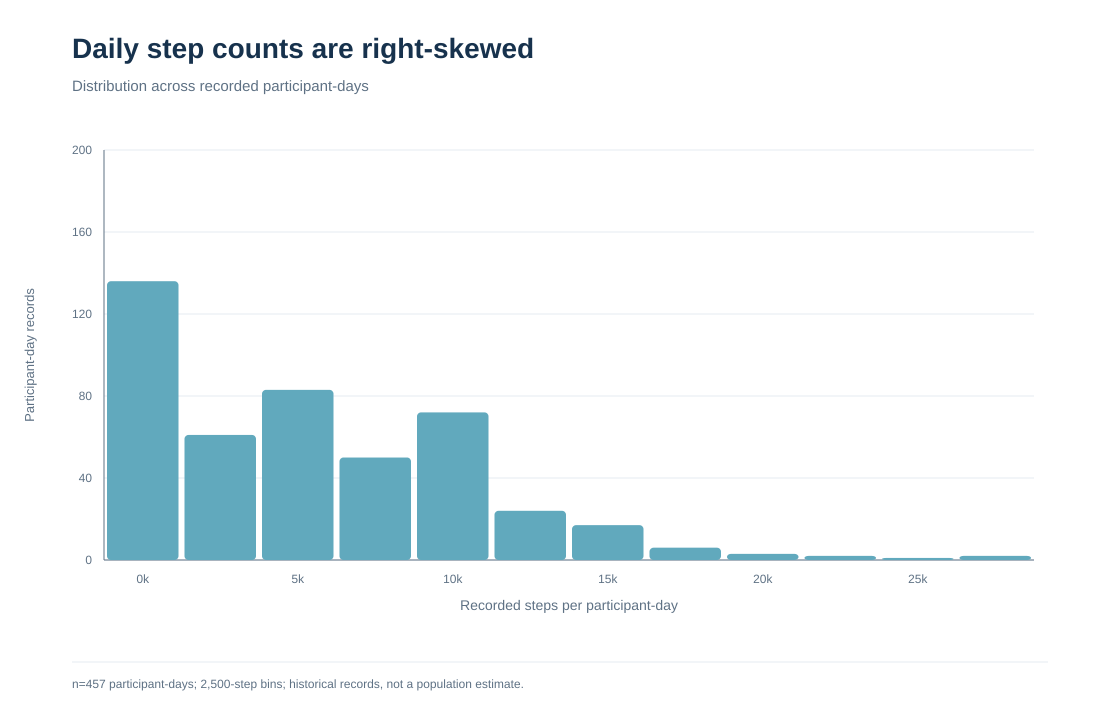

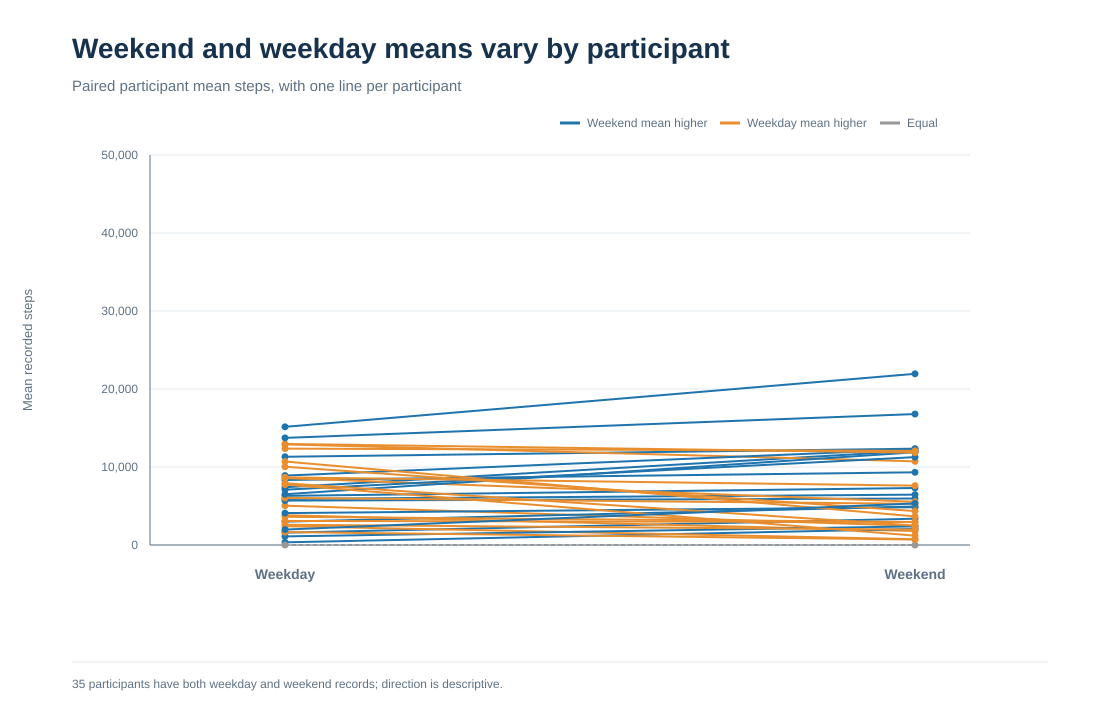

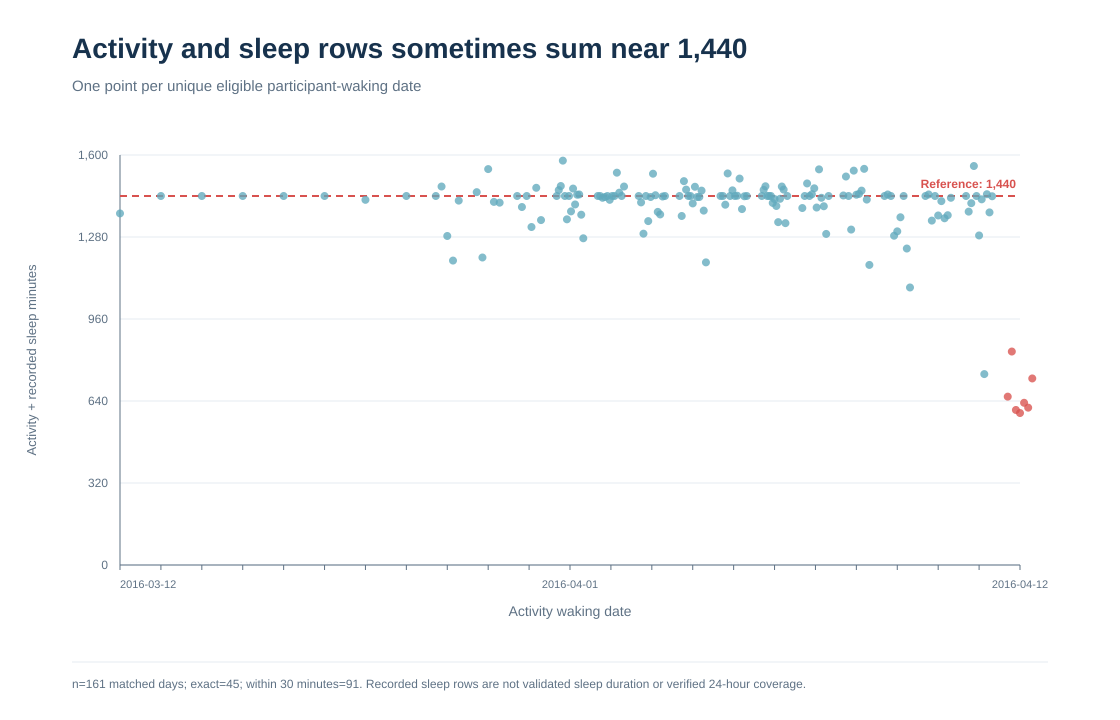

In [129]:
def table_html(rows):
    if not rows:return '<em>No rows</em>'
    columns=list(rows[0])
    return '<table><tr>'+''.join(f'<th>{html.escape(c)}</th>' for c in columns)+'</tr>'+''.join('<tr>'+''.join(f'<td>{html.escape(str(r.get(c,"")))}</td>' for c in columns)+'</tr>' for r in rows)+'</table>'
def compare_tree(generated,reference,suffixes):
    files=sorted(p.relative_to(generated) for p in generated.rglob('*') if p.is_file() and p.suffix in suffixes)
    return [(str(rel),generated.joinpath(rel).read_bytes()==(reference/rel).read_bytes()) for rel in files]
table_checks=compare_tree(TABLE_DIR,ROOT/'reports/generated/eda/tables',{'.csv'})
figure_checks=compare_tree(FIGURE_DIR,ROOT/'reports/generated/eda/figures',{'.svg'})
assert len(table_checks)==13 and all(ok for _,ok in table_checks),table_checks
assert len(figure_checks)==9 and all(ok for _,ok in figure_checks),figure_checks
assert json.loads((EVIDENCE_DIR/'run_manifest.json').read_text())['status']=='PASS'
print('FITINSIGHT_PROOF | P3-NOTEBOOK | exact_tables=%d | exact_generated_SVGs=%d | PASS' % (len(table_checks),len(figure_checks)))
with (TABLE_DIR/'descriptive_statistics.csv').open(encoding='utf-8',newline='') as stream: display(HTML('<h4>Descriptive statistics</h4>'+table_html(list(csv.DictReader(stream))[:8])))
print('Recorded-time accounting:',json.dumps(time_metrics['primary_summary'],indent=2))
for name in ('01_daily_steps_distribution.svg','04_weekday_weekend_paired_steps.svg','09_time_accounting_by_date.svg'):display(SVG(filename=str(FIGURE_DIR/name)))

## Findings and limitations
Sleep episode counts are not sleep duration. Time-accounting compares logged minutes and calendar dates but does not verify 24-hour device wear. Outlier flags are candidates for review, not confirmed errors. The exact table and figure parity checks above compare this notebook run with the validated Phase 3 artifacts.